In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob
import time
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import os,json,time,random,warnings
import torch
import torch.nn as nn
from torch.utils.data import WeightedRandomSampler
from torch.utils.data import TensorDataset,DataLoader
from sklearn.preprocessing import LabelEncoder,label_binarize
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import matthews_corrcoef
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,classification_report,confusion_matrix,ConfusionMatrixDisplay,roc_curve,precision_recall_curve,auc,matthews_corrcoef,cohen_kappa_score
warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore")

Mounted at /content/drive


In [2]:
DATASET_PATH = r"/content/drive/MyDrive/DATASET"
SEED = 42
print("Dataset path exists:", os.path.exists(DATASET_PATH))

Dataset path exists: True


In [ ]:
files = glob.glob(os.path.join(DATASET_PATH, "**", "*-training.parquet"), recursive=True)
print("Total training parquet files:", len(files))
for i, file in enumerate(files, 1):
    print(f"{i}. {os.path.basename(file)}")
if not files:
    raise ValueError("Training parquet files not found.")

Total training parquet files: 7
1. LDAP-training.parquet
2. MSSQL-training.parquet
3. NetBIOS-training.parquet
4. Portmap-training.parquet
5. Syn-training.parquet
6. UDP-training.parquet
7. UDPLag-training.parquet


In [ ]:
train_files, test_prefixes = [], set()
for root, _, files in os.walk(DATASET_PATH):
    for file in files:
        if file.endswith(".parquet"):
            filepath = os.path.join(root, file)
            if "-training" in file:
                train_files.append(filepath)
            elif "-testing" in file:
                test_prefixes.add(os.path.basename(file).split("-")[0])

common_train_files = [f for f in train_files if os.path.basename(f).split("-")[0] in test_prefixes]
if not common_train_files:
    raise ValueError("No matching training files found. Check the filenames and prefixes.")
dataframes = []
for filepath in sorted(common_train_files):
    df = pd.read_parquet(filepath)
    dataframes.append(df)
data = pd.concat(dataframes, ignore_index=True)

In [ ]:
display(data.head(10))

,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,17,49,2,0,458.0,0.0,229.0,229.0,229.0,0.0,...,8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NetBIOS
1,17,1,2,0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,...,1480,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,LDAP
2,17,1,2,0,458.0,0.0,229.0,229.0,229.0,0.0,...,14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NetBIOS
3,17,1,2,0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,...,14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,LDAP
4,17,1,2,0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,...,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,LDAP
5,17,2,2,0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,...,1396,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,LDAP
6,17,49,2,0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,...,1480,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,LDAP
7,17,1,2,0,2848.0,0.0,1424.0,1424.0,1424.0,0.0,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,LDAP
8,17,1,2,0,458.0,0.0,229.0,229.0,229.0,0.0,...,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NetBIOS
9,17,1,2,0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,LDAP


In [ ]:
data.shape

(120065, 78)

In [ ]:
print("Dataset Shape:", data.shape)
print("Total Rows:", data.shape[0])
print("Total Columns:", data.shape[1])

Dataset Shape: (120065, 78)
Total Rows: 120065
Total Columns: 78


In [ ]:
column_info = pd.DataFrame({
    "Column Name": data.columns,
    "Data Type": data.dtypes.astype(str).values,
    "Null Count": data.isnull().sum().values})

column_info = column_info[column_info["Null Count"] > 0].reset_index(drop=True)

display(column_info)

,Column Name,Data Type,Null Count


In [ ]:
print("Duplicate rows before removal:", data.duplicated().sum())
data = data.drop_duplicates().reset_index(drop=True)
print("Shape after duplicate removal:", data.shape)
print("Duplicate rows after removal:", data.duplicated().sum())

Duplicate rows before removal: 3195
Shape after duplicate removal: (116870, 78)
Duplicate rows after removal: 0


In [ ]:
print(data["Label"].value_counts())

Label
Syn        47246
Benign     40980
UDP        17795
MSSQL       8434
LDAP        1885
NetBIOS      475
UDPLag        55
Name: count, dtype: int64


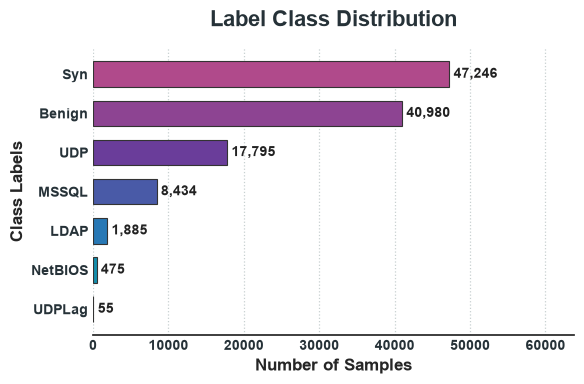

In [ ]:

label_counts = data["Label"].value_counts().sort_values(ascending=True)

categories, values = label_counts.index, label_counts.values

colors = sns.blend_palette(
    ["#00A6A6", "#2878B5", "#6A3D9A", "#B04A8B"],
    n_colors=len(values)
)

sns.set_theme(style="ticks")

fig, ax = plt.subplots(figsize=(6, 4))
fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

bars = ax.barh(
    y=categories,
    width=values,
    color=colors,
    height=0.65,
    edgecolor="#333333",
    linewidth=0.8,
    zorder=3
)

offset = max(values) * 0.012

for bar, val in zip(bars, values):
    ax.text(
        bar.get_width() + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{val:,}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
        color="#222222"
    )

ax.set_title(
    "Label Class Distribution",
    fontsize=16,
    fontweight="bold",
    color="#263238",
    pad=16
)

ax.set_xlabel("Number of Samples", fontsize=12, fontweight="bold")
ax.set_ylabel("Class Labels", fontsize=12, fontweight="bold")

ax.tick_params(axis="both", labelsize=10, length=0)

for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight("bold")
    label.set_color("#263238")

ax.set_axisbelow(True)
ax.grid(axis="x", linestyle=":", linewidth=0.9,
        color="#AAB7B8", alpha=0.65)
ax.grid(axis="y", visible=False)

sns.despine(ax=ax, top=True, right=True, left=True)
ax.set_xlim(0, max(values) * 1.35)

plt.tight_layout()
plt.show()


In [ ]:
X = data.drop(columns=["Label"]).select_dtypes(include="number")
X = X.replace([float("inf"), -float("inf")], float("nan"))
y = data.loc[X.index, "Label"]
valid_rows = X.notna().any(axis=1)
X = X.loc[valid_rows].reset_index(drop=True)
y = y.loc[valid_rows].reset_index(drop=True)
if X.empty or y.nunique() < 2:
    raise ValueError("Insufficient valid features or classes.")
class_counts = y.value_counts()
if (class_counts < 2).any():
    raise ValueError(f"Each class needs at least 2 samples:\n{class_counts[class_counts < 2]}")
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.30, random_state=SEED, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.20, random_state=SEED, stratify=y_dev)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (65447, 77)
Validation: (16362, 77)
Test: (35061, 77)


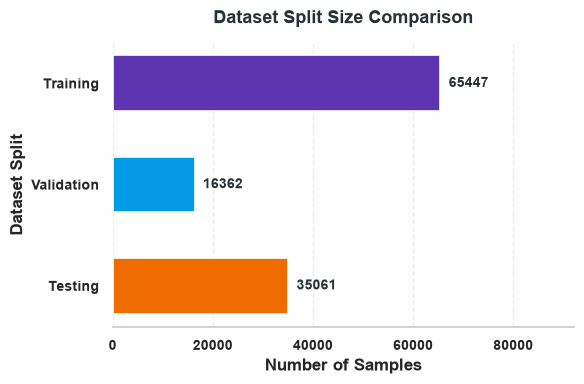

In [ ]:
sns.set_style("whitegrid")
split_sizes = pd.Series({"Training": len(X_train), "Validation": len(X_val), "Testing": len(X_test)})
fig, ax = plt.subplots(figsize=(6, 4))
bar_colors = ["#5E35B1", "#039BE5", "#EF6C00"]
bars = ax.barh(split_sizes.index, split_sizes.values, color=bar_colors, edgecolor="white", linewidth=1.2, height=0.55)
ax.bar_label(bars, fmt="%d", padding=6, fontsize=10, fontweight="bold", color="#263238")
ax.set_title("Dataset Split Size Comparison", fontsize=13, fontweight="bold", pad=14, color="#263238")
ax.set_xlabel("Number of Samples", fontsize=12, fontweight="bold")
ax.set_ylabel("Dataset Split", fontsize=12, fontweight="bold")
plt.setp(ax.get_xticklabels(), fontsize=10, fontweight="bold")
plt.setp(ax.get_yticklabels(), fontsize=10, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(values) * 1.95)
ax.invert_yaxis()
sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()

In [ ]:
print("\nCLASS COUNTS ")
print(pd.DataFrame({"Overall": y.value_counts(), "Train": y_train.value_counts(),
                    "Validation": y_val.value_counts(),
                    "Test": y_test.value_counts()}).fillna(0).astype(int))


CLASS COUNTS 
         Overall  Train  Validation   Test
Label                                     
Syn        47246  26458        6614  14174
Benign     40980  22949        5737  12294
UDP        17795   9965        2491   5339
MSSQL       8434   4723        1181   2530
LDAP        1885   1055         264    566
NetBIOS      475    266          67    142
UDPLag        55     31           8     16


In [ ]:
POPULATION = 20
ITERATIONS = 40
ALPHA = 0.01
SEED = 42
OUTPUT_DIR = "MAO_Feature_Selection_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)
start_time = time.time()
rng = np.random.default_rng(SEED)

feature_names = X_train.columns.astype(str).tolist() if isinstance(X_train, pd.DataFrame) else [f"Feature_{i+1}" for i in range(np.asarray(X_train).shape[1])]
X_tr = np.asarray(X_train, dtype=np.float32).copy()
X_va = np.asarray(X_val, dtype=np.float32).copy()
X_te = np.asarray(X_test, dtype=np.float32).copy()
y_tr = np.asarray(y_train).ravel()
y_va = np.asarray(y_val).ravel()
y_te = np.asarray(y_test).ravel()
n_features = X_tr.shape[1]

if X_tr.ndim != 2 or X_va.ndim != 2 or X_te.ndim != 2:
    raise ValueError("Train, validation and test must be 2D arrays.")
if X_va.shape[1] != n_features or X_te.shape[1] != n_features:
    raise ValueError("Train, validation and test feature counts differ.")
if len(feature_names) != n_features:
    raise ValueError("Feature names count does not match X_train.")
if len(y_tr) != len(X_tr) or len(y_va) != len(X_va) or len(y_te) != len(X_te):
    raise ValueError("Input data and label counts do not match.")
if n_features == 0:
    raise ValueError("No input features were found.")

print("MAO FEATURE SELECTION - INPUT DETAILS")
print("Training Shape:", X_tr.shape)
print("Validation Shape:", X_va.shape)
print("Testing Shape:", X_te.shape)
print("Original Feature Count:", n_features)
print("Number of Classes:", len(np.unique(y_tr)))

X_tr[~np.isfinite(X_tr)] = np.nan
X_va[~np.isfinite(X_va)] = np.nan
X_te[~np.isfinite(X_te)] = np.nan
train_medians = np.zeros(n_features, dtype=np.float32)

for j in range(n_features):
    valid_values = X_tr[np.isfinite(X_tr[:, j]), j]
    if len(valid_values) > 0:
        train_medians[j] = np.median(valid_values)
    X_tr[np.isnan(X_tr[:, j]), j] = train_medians[j]
    X_va[np.isnan(X_va[:, j]), j] = train_medians[j]
    X_te[np.isnan(X_te[:, j]), j] = train_medians[j]

fitness_cache = {}

def evaluate_fitness(mask):
    mask = np.asarray(mask, dtype=bool)
    selected_count = int(mask.sum())
    if selected_count == 0:
        return float("inf")
    key = mask.tobytes()
    if key not in fitness_cache:
        model = RandomForestClassifier(n_estimators=50, random_state=SEED, n_jobs=-1)
        model.fit(X_tr[:, mask], y_tr)
        val_pred = model.predict(X_va[:, mask])
        val_accuracy = accuracy_score(y_va, val_pred)
        validation_error = 1.0 - val_accuracy
        feature_penalty = ALPHA * (selected_count / n_features)
        fitness_cache[key] = float(validation_error + feature_penalty)
    return fitness_cache[key]

print("MAO INITIALIZATION")
population = rng.integers(0, 2, size=(POPULATION, n_features)).astype(bool)
for i in range(POPULATION):
    if not population[i].any():
        population[i, rng.integers(0, n_features)] = True
fitness_values = np.array([evaluate_fitness(individual) for individual in population])
best_index = int(np.argmin(fitness_values))
best_mask = population[best_index].copy()
best_fitness = float(fitness_values[best_index])
convergence_curve = [best_fitness]
print("Population Size:", POPULATION)
print("Number of Iterations:", ITERATIONS)
print("Original Features:", n_features)
print("Initial Best Fitness:", f"{best_fitness:.8f}")
print("Initial Selected Features:", int(best_mask.sum()))

print("MAO OPTIMIZATION")

for iteration in range(ITERATIONS):
    new_population = population.copy()
    exploration_rate = 1.0 - iteration / max(ITERATIONS, 1)
    exploitation_rate = 0.20 + 0.60 * iteration / max(ITERATIONS - 1, 1)
    for i in range(POPULATION):
        candidate = population[i].copy()
        flip_count = max(1, int(exploration_rate * n_features * 0.10))
        flip_count = min(flip_count, n_features)
        flip_indices = rng.choice(n_features, size=flip_count, replace=False)
        candidate[flip_indices] = ~candidate[flip_indices]
        follow_mask = rng.random(n_features) < exploitation_rate
        candidate[follow_mask] = best_mask[follow_mask]
        if not candidate.any():
            candidate[rng.integers(0, n_features)] = True
        new_population[i] = candidate
    new_fitness_values = np.array([evaluate_fitness(individual) for individual in new_population])
    for i in range(POPULATION):
        if new_fitness_values[i] <= fitness_values[i]:
            population[i] = new_population[i].copy()
            fitness_values[i] = new_fitness_values[i]
    current_best_index = int(np.argmin(fitness_values))
    current_best_fitness = float(fitness_values[current_best_index])
    if current_best_fitness < best_fitness:
        best_fitness = current_best_fitness
        best_mask = population[current_best_index].copy()
    best_fitness = min(best_fitness, convergence_curve[-1])
    convergence_curve.append(best_fitness)
    print(f"Iteration {iteration + 1:02d}/{ITERATIONS} | Best Fitness: {best_fitness:.8f} | Selected Features: {int(best_mask.sum())} | Exploration: {exploration_rate:.3f} | Exploitation: {exploitation_rate:.3f}")

selected_mask = best_mask.copy()
selected_indices = np.flatnonzero(selected_mask)
selected_features = [feature_names[i] for i in selected_indices]
X_train_MAO = X_tr[:, selected_indices].copy()
X_val_MAO = X_va[:, selected_indices].copy()
X_test_MAO = X_te[:, selected_indices].copy()

fitness_differences = np.diff(convergence_curve)
is_monotonic = bool(np.all(fitness_differences <= 1e-12))
assert is_monotonic, "ERROR: Best-so-far fitness increased!"

execution_time = time.time() - start_time

MAO FEATURE SELECTION - INPUT DETAILS
Training Shape: (65447, 77)
Validation Shape: (16362, 77)
Testing Shape: (35061, 77)
Original Feature Count: 77
Number of Classes: 7
MAO INITIALIZATION
Population Size: 20
Number of Iterations: 40
Original Features: 77
Initial Best Fitness: 0.01199409
Initial Selected Features: 42
MAO OPTIMIZATION
Iteration 01/40 | Best Fitness: 0.01093222 | Selected Features: 31 | Exploration: 1.000 | Exploitation: 0.200
Iteration 02/40 | Best Fitness: 0.01004604 | Selected Features: 27 | Exploration: 0.975 | Exploitation: 0.215
Iteration 03/40 | Best Fitness: 0.01004604 | Selected Features: 27 | Exploration: 0.950 | Exploitation: 0.231
Iteration 04/40 | Best Fitness: 0.01004604 | Selected Features: 27 | Exploration: 0.925 | Exploitation: 0.246
Iteration 05/40 | Best Fitness: 0.00983978 | Selected Features: 24 | Exploration: 0.900 | Exploitation: 0.262
Iteration 06/40 | Best Fitness: 0.00983978 | Selected Features: 24 | Exploration: 0.875 | Exploitation: 0.277
Ite

In [ ]:

print("MAO SELECTED FEATURE NAMES")


print(f"Total Selected Features: {len(selected_features)}\n")

for i, feature in enumerate(selected_features, start=1):
    print(f"{i}. {feature}")


MAO SELECTED FEATURE NAMES
Total Selected Features: 7

1. Fwd Packet Length Min
2. Flow IAT Std
3. Packet Length Max
4. ACK Flag Count
5. CWE Flag Count
6. Avg Packet Size
7. Subflow Bwd Packets


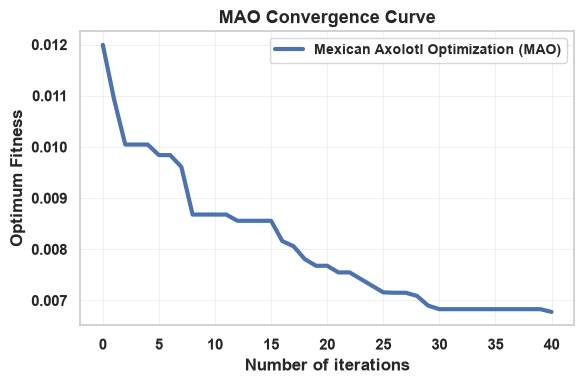

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(range(len(convergence_curve)),convergence_curve,linewidth=3,label="Mexican Axolotl Optimization (MAO)",)
plt.xlabel("Number of iterations", fontsize=12, fontweight="bold")
plt.ylabel("Optimum Fitness", fontsize=12, fontweight="bold")
plt.title("MAO Convergence Curve", fontsize=13, fontweight="bold")

plt.xticks(fontweight="bold")
plt.yticks(fontweight="bold")
plt.grid(True, linestyle="-", linewidth=0.5, color="#e0e0e0", alpha=0.7)
plt.legend(loc="upper right", frameon=True,
           prop={"weight": "bold", "size": 10})
plt.tight_layout()
plt.show()
plt.close()

In [ ]:
if isinstance(X_train, pd.DataFrame):
    X_train_df = X_train.copy()
    X_val_df = X_val.copy() if isinstance(X_val, pd.DataFrame) else pd.DataFrame(X_val, columns=X_train.columns)
    X_test_df = X_test.copy() if isinstance(X_test, pd.DataFrame) else pd.DataFrame(X_test, columns=X_train.columns)
else:
    X_train_df = pd.DataFrame(X_train)
    X_val_df = pd.DataFrame(X_val)
    X_test_df = pd.DataFrame(X_test)

if not (X_train_df.shape[1] == X_val_df.shape[1] == X_test_df.shape[1]):
    raise ValueError("Train, validation and test feature counts differ.")

train_mean = X_train_df.mean()
train_std = X_train_df.std(ddof=0).replace(0, 1).fillna(1)

X_train = ((X_train_df - train_mean) / train_std).to_numpy(dtype=np.float32)
X_val = ((X_val_df - train_mean) / train_std).to_numpy(dtype=np.float32)
X_test = ((X_test_df - train_mean) / train_std).to_numpy(dtype=np.float32)

print("Z-score normalization completed successfully.")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Z-score normalization completed successfully.
Train: (65447, 77)
Validation: (16362, 77)
Test: (35061, 77)


In [ ]:
SEEDS=[42,56,67,123,245]
BATCH_SIZE=64
EPOCHS=10
PATIENCE=8
LEARNING_RATE=0.0001
WEIGHT_DECAY=1e-4
D_MODEL=64
NUM_HEADS=4
NUM_TRANSFORMER_LAYERS=2
GRU_HIDDEN=64
DROPOUT=0.30
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
required_variables=["X_train_MAO","X_val_MAO","X_test_MAO","y_train","y_val","y_test"]
missing_variables=[v for v in required_variables if v not in globals()]
if missing_variables: raise NameError("Run the MAO feature-selection cell first. Missing: "+", ".join(missing_variables))
def convert_features_to_numpy(data):
    if isinstance(data,(pd.DataFrame,pd.Series)): data=data.to_numpy()
    data=np.asarray(data,dtype=np.float32)
    if data.ndim==1: data=data.reshape(-1,1)
    if data.ndim!=2: raise ValueError(f"Expected 2D features, received {data.shape}")
    return np.nan_to_num(data,nan=0.0,posinf=0.0,neginf=0.0)
X_train_np=convert_features_to_numpy(X_train_MAO)
X_val_np=convert_features_to_numpy(X_val_MAO)
X_test_np=convert_features_to_numpy(X_test_MAO)
y_train_raw=np.asarray(y_train).reshape(-1)
y_val_raw=np.asarray(y_val).reshape(-1)
y_test_raw=np.asarray(y_test).reshape(-1)
if not(len(X_train_np)==len(y_train_raw) and len(X_val_np)==len(y_val_raw) and len(X_test_np)==len(y_test_raw)): raise ValueError("Feature and label sample counts do not match.")
if not(X_train_np.shape[1]==X_val_np.shape[1]==X_test_np.shape[1]): raise ValueError("Feature counts do not match.")
INPUT_DIM=X_train_np.shape[1]
label_encoder=LabelEncoder()
label_encoder.fit(np.concatenate([y_train_raw,y_val_raw,y_test_raw]))
y_train_encoded=label_encoder.transform(y_train_raw)
y_val_encoded=label_encoder.transform(y_val_raw)
y_test_encoded=label_encoder.transform(y_test_raw)
class_names=label_encoder.classes_.astype(str).tolist()
NUM_CLASSES=len(class_names)
train_class_counts=np.bincount(y_train_encoded,minlength=NUM_CLASSES)
present_classes=np.unique(y_train_encoded)
class_weights_np=np.ones(NUM_CLASSES,dtype=np.float32)
class_weights_np[present_classes]=compute_class_weight(class_weight="balanced",classes=present_classes,y=y_train_encoded)
class_weights=torch.tensor(class_weights_np,dtype=torch.float32,device=DEVICE)
X_train_tensor=torch.tensor(X_train_np,dtype=torch.float32)
X_val_tensor=torch.tensor(X_val_np,dtype=torch.float32)
X_test_tensor=torch.tensor(X_test_np,dtype=torch.float32)
y_train_tensor=torch.tensor(y_train_encoded,dtype=torch.long)
y_val_tensor=torch.tensor(y_val_encoded,dtype=torch.long)
y_test_tensor=torch.tensor(y_test_encoded,dtype=torch.long)
train_dataset=TensorDataset(X_train_tensor,y_train_tensor)
val_dataset=TensorDataset(X_val_tensor,y_val_tensor)
test_dataset=TensorDataset(X_test_tensor,y_test_tensor)

print("HYBRIDQBiDR_NALT - CLASS-WEIGHTED TRAINING")
print("Device:",DEVICE)
print("Seeds:",SEEDS)
print("Train:",X_train_np.shape,"Validation:",X_val_np.shape,"Test:",X_test_np.shape)
print("Input Features:",INPUT_DIM,"Number of Classes:",NUM_CLASSES)
print("Class Names:",class_names)
print("\nTraining Class Counts and Weights")
for i,name in enumerate(class_names): print(f"{name}: Count={train_class_counts[i]}, Weight={class_weights_np[i]:.6f}")

HYBRIDQBiDR_NALT - CLASS-WEIGHTED TRAINING
Device: cpu
Seeds: [42, 56, 67, 123, 245]
Train: (65447, 7) Validation: (16362, 7) Test: (35061, 7)
Input Features: 7 Number of Classes: 7
Class Names: ['Benign', 'LDAP', 'MSSQL', 'NetBIOS', 'Syn', 'UDP', 'UDPLag']

Training Class Counts and Weights
Benign: Count=22949, Weight=0.407406
LDAP: Count=1055, Weight=8.862153
MSSQL: Count=4723, Weight=1.979583
NetBIOS: Count=266, Weight=35.148766
Syn: Count=26458, Weight=0.353374
UDP: Count=9965, Weight=0.938241
UDPLag: Count=31, Weight=301.599091


In [ ]:
class NALUInspiredBlock(nn.Module):
    def __init__(self,input_dim,output_dim):
        super().__init__()
        self.W_hat=nn.Parameter(torch.empty(input_dim,output_dim))
        self.M_hat=nn.Parameter(torch.empty(input_dim,output_dim))
        self.G=nn.Linear(input_dim,output_dim)
        nn.init.xavier_uniform_(self.W_hat)
        nn.init.xavier_uniform_(self.M_hat)
    def forward(self,x):
        W=torch.tanh(self.W_hat)*torch.sigmoid(self.M_hat)
        additive=torch.matmul(x,W)
        multiplicative=torch.exp(torch.matmul(torch.log(torch.abs(x)+1e-7),W))
        multiplicative=torch.nan_to_num(multiplicative,nan=0.0,posinf=1e4,neginf=0.0).clamp(-1e4,1e4)
        gate=torch.sigmoid(self.G(x))
        return torch.nan_to_num(gate*additive+(1-gate)*multiplicative,nan=0.0,posinf=1e4,neginf=-1e4)
class QuantumInspiredBranch(nn.Module):
    def __init__(self,input_dim,output_dim,dropout=0.3):
        super().__init__()
        self.projection=nn.Linear(input_dim,output_dim)
        self.phase_projection=nn.Linear(input_dim,output_dim)
        self.fusion=nn.Sequential(nn.Linear(output_dim*2,output_dim),nn.GELU(),nn.Dropout(dropout),nn.LayerNorm(output_dim))
    def forward(self,x):
        return self.fusion(torch.cat([torch.sin(self.projection(x)),torch.cos(self.phase_projection(x))],dim=1))
class HYBRIDQBiDR_NALT(nn.Module):
    def __init__(self,input_dim,num_classes,d_model=64,num_heads=4,num_transformer_layers=2,gru_hidden=64,dropout=0.30):
        super().__init__()
        self.feature_embedding=nn.Linear(1,d_model)
        self.position_embedding=nn.Parameter(torch.randn(1,input_dim,d_model)*0.02)
        layer=nn.TransformerEncoderLayer(d_model=d_model,nhead=num_heads,dim_feedforward=d_model*2,dropout=dropout,activation="gelu",batch_first=True,norm_first=True)
        self.transformer=nn.TransformerEncoder(layer,num_layers=num_transformer_layers)
        self.transformer_norm=nn.LayerNorm(d_model)
        self.quantum_branch=QuantumInspiredBranch(input_dim,d_model,dropout)
        self.gru_input_projection=nn.Linear(1,d_model)
        self.bigru=nn.GRU(d_model,gru_hidden,batch_first=True,bidirectional=True)
        self.gru_norm=nn.LayerNorm(gru_hidden*2)
        self.gru_projection=nn.Sequential(nn.Linear(gru_hidden*2,d_model),nn.GELU(),nn.Dropout(dropout))
        self.nalu_branch=nn.Sequential(NALUInspiredBlock(input_dim,d_model),nn.LayerNorm(d_model),nn.GELU(),nn.Dropout(dropout))
        self.fusion=nn.Sequential(nn.Linear(d_model*4,d_model*2),nn.LayerNorm(d_model*2),nn.GELU(),nn.Dropout(dropout),nn.Linear(d_model*2,d_model),nn.LayerNorm(d_model),nn.GELU(),nn.Dropout(dropout))
        self.classifier=nn.Linear(d_model,num_classes)
    def forward(self,x):
        t=self.transformer_norm(self.transformer(self.feature_embedding(x.unsqueeze(-1))+self.position_embedding)).mean(dim=1)
        q=self.quantum_branch(x)
        g,_=self.bigru(self.gru_input_projection(x.unsqueeze(-1)))
        g=self.gru_projection(self.gru_norm(g).mean(dim=1))
        n=self.nalu_branch(x)
        return self.classifier(self.fusion(torch.cat([t,q,g,n],dim=1)))
def evaluate_model(model,data_loader,criterion):
    model.eval()
    total_loss=0.0
    total_samples=0
    labels,predictions,probabilities=[],[],[]
    with torch.no_grad():
        for bx,by in data_loader:
            bx,by=bx.to(DEVICE),by.to(DEVICE)
            logits=model(bx)
            loss=criterion(logits,by)
            probs=torch.softmax(logits,dim=1)
            total_loss+=loss.item()*by.size(0)
            total_samples+=by.size(0)
            labels.extend(by.cpu().numpy())
            predictions.extend(probs.argmax(dim=1).cpu().numpy())
            probabilities.extend(probs.cpu().numpy())
    yt=np.asarray(labels)
    yp=np.asarray(predictions)
    yp_prob=np.asarray(probabilities)
    metrics={"Loss":total_loss/max(total_samples,1),"Accuracy":accuracy_score(yt,yp),"Precision_Macro":precision_score(yt,yp,average="macro",zero_division=0),"Recall_Macro":recall_score(yt,yp,average="macro",zero_division=0),"F1_Macro":f1_score(yt,yp,average="macro",zero_division=0),"Precision_Weighted":precision_score(yt,yp,average="weighted",zero_division=0),"Recall_Weighted":recall_score(yt,yp,average="weighted",zero_division=0),"F1_Weighted":f1_score(yt,yp,average="weighted",zero_division=0)}
    try:
        if NUM_CLASSES==2:
            metrics["ROC_AUC"]=roc_auc_score(yt,yp_prob[:,1])
            metrics["Average_Precision"]=average_precision_score(yt,yp_prob[:,1])
        else:
            ybin=label_binarize(yt,classes=np.arange(NUM_CLASSES))
            metrics["ROC_AUC"]=roc_auc_score(ybin,yp_prob,average="macro",multi_class="ovr")
            metrics["Average_Precision"]=average_precision_score(ybin,yp_prob,average="macro")
    except (ValueError,IndexError): metrics["ROC_AUC"]=np.nan; metrics["Average_Precision"]=np.nan
    return metrics,yt,yp,yp_prob

In [ ]:
all_results=[]
seed_outputs={}
overall_start_time=time.time()
for seed in SEEDS:
    print(f"TRAINING SEED: {seed}")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    generator=torch.Generator().manual_seed(seed)
    train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,generator=generator,num_workers=0)
    val_loader=DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
    test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
    model=HYBRIDQBiDR_NALT(INPUT_DIM,NUM_CLASSES,D_MODEL,NUM_HEADS,NUM_TRANSFORMER_LAYERS,GRU_HIDDEN,DROPOUT).to(DEVICE)
    criterion=nn.CrossEntropyLoss(weight=class_weights)
    optimizer=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode="min",factor=0.5,patience=2)
    history={"train_loss":[],"val_loss":[],"train_accuracy":[],"val_accuracy":[],"learning_rate":[]}
    best_val_loss=float("inf")
    best_epoch=0
    best_state=None
    patience_counter=0
    start_time=time.time()
    for epoch in range(EPOCHS):
        model.train()
        running_loss=0.0
        running_correct=0
        running_samples=0
        for bx,by in train_loader:
            bx,by=bx.to(DEVICE),by.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits=model(bx)
            loss=criterion(logits,by)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=1.0)
            optimizer.step()
            n=by.size(0)
            running_loss+=loss.item()*n
            running_correct+=(logits.detach().argmax(dim=1)==by).sum().item()
            running_samples+=n
        train_loss=running_loss/max(running_samples,1)
        train_accuracy=running_correct/max(running_samples,1)
        val_metrics,_,_,_=evaluate_model(model,val_loader,criterion)
        val_loss=val_metrics["Loss"]
        val_accuracy=val_metrics["Accuracy"]
        scheduler.step(val_loss)
        lr=optimizer.param_groups[0]["lr"]
        history["train_loss"].append(float(train_loss))
        history["val_loss"].append(float(val_loss))
        history["train_accuracy"].append(float(train_accuracy))
        history["val_accuracy"].append(float(val_accuracy))
        history["learning_rate"].append(float(lr))
        print(f"Seed {seed} | Epoch {epoch+1:02d}/{EPOCHS} | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f} | Train Acc: {train_accuracy:.4f} | Val Acc: {val_accuracy:.4f} | LR: {lr:.7f}")
        if val_loss<best_val_loss:
            best_val_loss=val_loss
            best_epoch=epoch+1
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            patience_counter=0
        else:
            patience_counter+=1
        if patience_counter>=PATIENCE:
            print(f"Early stopping at epoch {epoch+1} for seed {seed}")
            break
    training_time=time.time()-start_time
    model.load_state_dict(best_state)
    val_metrics,val_true,val_pred,val_prob=evaluate_model(model,val_loader,criterion)
    test_metrics,test_true,test_pred,test_prob=evaluate_model(model,test_loader,criterion)
    seed_outputs[seed]={"model_state":best_state,"history":history,"best_epoch":best_epoch,"best_val_loss":best_val_loss,"training_time":training_time,"validation_metrics":val_metrics,"validation_true":val_true,"validation_pred":val_pred,"validation_prob":val_prob,"test_metrics":test_metrics,"test_true":test_true,"test_pred":test_pred,"test_prob":test_prob}
    result={"Seed":seed,"Best_Epoch":best_epoch,"Training_Time_Seconds":training_time,"Best_Validation_Loss":best_val_loss}
    result.update({f"Test_{k}":v for k,v in test_metrics.items()})
    result.update({f"Validation_{k}":v for k,v in val_metrics.items()})
    all_results.append(result)
    print(f"\nSeed {seed} completed | Best Epoch: {best_epoch} | Training Time: {training_time:.2f}s")
    print("Test Metrics:")
    for k,v in test_metrics.items(): print(f"{k}: {v:.6f}")
overall_training_time=time.time()-overall_start_time
results_df=pd.DataFrame(all_results)
print("ALL FIVE SEEDS TRAINING COMPLETED")
print(f"Total Training Time: {overall_training_time:.2f} seconds")
display(results_df)

TRAINING SEED: 42
Seed 42 | Epoch 01/10 | Train Loss: 1.108508 | Val Loss: 0.746662 | Train Acc: 0.6883 | Val Acc: 0.8699 | LR: 0.0001000
Seed 42 | Epoch 02/10 | Train Loss: 0.752493 | Val Loss: 0.579458 | Train Acc: 0.8485 | Val Acc: 0.9234 | LR: 0.0001000
Seed 42 | Epoch 03/10 | Train Loss: 0.614413 | Val Loss: 0.468294 | Train Acc: 0.8976 | Val Acc: 0.9292 | LR: 0.0001000
Seed 42 | Epoch 04/10 | Train Loss: 0.533863 | Val Loss: 0.447785 | Train Acc: 0.9132 | Val Acc: 0.9315 | LR: 0.0001000
Seed 42 | Epoch 05/10 | Train Loss: 0.474419 | Val Loss: 0.369892 | Train Acc: 0.9204 | Val Acc: 0.9462 | LR: 0.0001000
Seed 42 | Epoch 06/10 | Train Loss: 0.437297 | Val Loss: 0.331989 | Train Acc: 0.9293 | Val Acc: 0.9517 | LR: 0.0001000
Seed 42 | Epoch 07/10 | Train Loss: 0.396051 | Val Loss: 0.323700 | Train Acc: 0.9384 | Val Acc: 0.9573 | LR: 0.0001000
Seed 42 | Epoch 08/10 | Train Loss: 0.346611 | Val Loss: 0.262976 | Train Acc: 0.9545 | Val Acc: 0.9740 | LR: 0.0001000
Seed 42 | Epoch 09/10 

,Seed,Best_Epoch,Training_Time_Seconds,Best_Validation_Loss,Test_Loss,Test_Accuracy,Test_Precision_Macro,Test_Recall_Macro,Test_F1_Macro,Test_Precision_Weighted,...,Validation_Loss,Validation_Accuracy,Validation_Precision_Macro,Validation_Recall_Macro,Validation_F1_Macro,Validation_Precision_Weighted,Validation_Recall_Weighted,Validation_F1_Weighted,Validation_ROC_AUC,Validation_Average_Precision
0,42,9,256.210843,0.261906,0.235203,0.975329,0.774634,0.851428,0.800480,0.978795,...,0.261906,0.974697,0.765402,0.864018,0.796075,0.978308,0.974697,0.976085,0.966160,0.819793
1,56,10,262.278236,0.254169,0.233892,0.974502,0.766287,0.889768,0.794229,0.982091,...,0.254169,0.976164,0.775688,0.908347,0.802762,0.983229,0.976164,0.979085,0.980156,0.848960
2,67,9,260.731178,0.242326,0.227220,0.976013,0.774101,0.891962,0.801767,0.981942,...,0.242326,0.977264,0.781636,0.909550,0.808407,0.983019,0.977264,0.979718,0.968585,0.847711
3,123,10,261.605227,0.265965,0.221008,0.975757,0.781136,0.876727,0.805108,0.981951,...,0.265965,0.975370,0.765141,0.851219,0.790935,0.981387,0.975370,0.978001,0.974779,0.819209
4,245,10,261.227443,0.259883,0.238359,0.974188,0.768065,0.914773,0.794432,0.983494,...,0.259883,0.974514,0.760410,0.904818,0.788748,0.983698,0.974514,0.978450,0.973460,0.834803


In [ ]:
from sklearn.metrics import classification_report
for seed in SEEDS:
    output=seed_outputs[seed]
    print(f"CLASSIFICATION REPORT - SEED {seed}")
    print(classification_report(output["test_true"],output["test_pred"],labels=np.arange(NUM_CLASSES),target_names=class_names,digits=4,zero_division=0))

CLASSIFICATION REPORT - SEED 42
              precision    recall  f1-score   support

      Benign     0.9936    0.9882    0.9909     12294
        LDAP     0.8141    0.9205    0.8640       566
       MSSQL     0.8519    0.9415    0.8945      2530
     NetBIOS     0.7403    0.9437    0.8297       142
         Syn     0.9998    0.9933    0.9965     14174
         UDP     0.9756    0.9228    0.9485      5339
      UDPLag     0.0471    0.2500    0.0792        16

    accuracy                         0.9753     35061
   macro avg     0.7746    0.8514    0.8005     35061
weighted avg     0.9788    0.9753    0.9766     35061

CLASSIFICATION REPORT - SEED 56
              precision    recall  f1-score   support

      Benign     0.9934    0.9934    0.9934     12294
        LDAP     0.6941    0.9700    0.8091       566
       MSSQL     0.9026    0.8905    0.8965      2530
     NetBIOS     0.7514    0.9577    0.8421       142
         Syn     0.9998    0.9932    0.9965     14174
         UDP  

In [ ]:
seed_reports = []

for seed in SEEDS:
    output = seed_outputs[seed]

    report = classification_report(
        output["test_true"],
        output["test_pred"],
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    seed_reports.append(report)

report_keys = class_names + ["macro avg", "weighted avg"]

average_report = {}

for key in report_keys:
    average_report[key] = {
        metric: np.mean([
            report[key][metric] for report in seed_reports
        ])
        for metric in ["precision", "recall", "f1-score"]
    }

for key in report_keys:
    average_report[key]["support"] = np.mean([
        report[key]["support"] for report in seed_reports
    ])

average_report["accuracy"] = np.mean([
    report["accuracy"] for report in seed_reports
])

average_df = pd.DataFrame(average_report).T

display(
    average_df.style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1-score": "{:.4f}",
        "support": "{:.2f}"
    }).set_caption("Mean Classification Metrics Across Five Seeds")
)


,precision,recall,f1-score,support
Benign,0.9937,0.9910,0.9923,12294.00
LDAP,0.7512,0.9618,0.8426,566.00
MSSQL,0.8963,0.9079,0.9015,2530.00
NetBIOS,0.7506,0.9521,0.8391,142.00
Syn,0.9998,0.9934,0.9966,14174.00
UDP,0.9797,0.9258,0.9520,5339.00
UDPLag,0.0387,0.4625,0.0703,16.00
macro avg,0.7728,0.8849,0.7992,35061.00
weighted avg,0.9817,0.9752,0.9779,35061.00
accuracy,0.9752,0.9752,0.9752,0.98


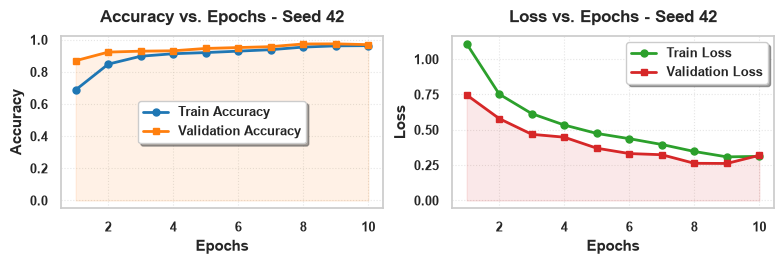

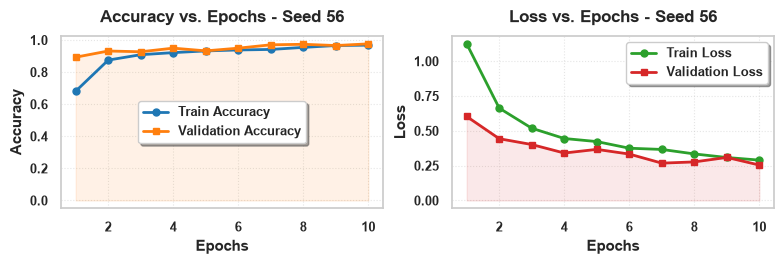

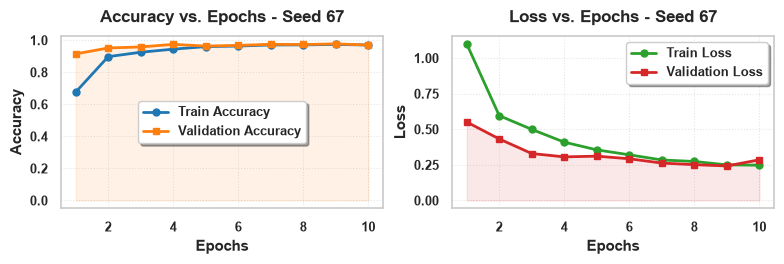

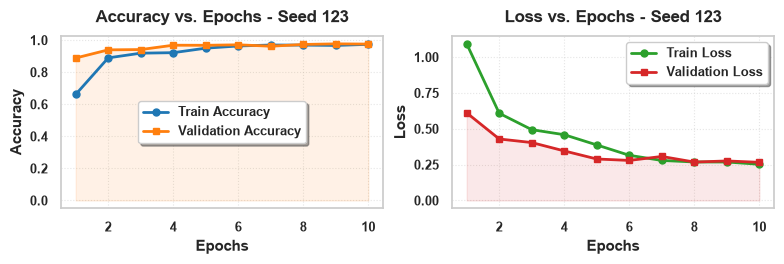

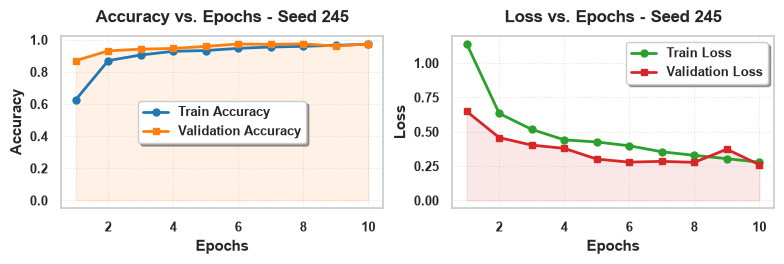

In [ ]:
for seed in SEEDS:
    history = seed_outputs[seed]["history"]
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 2.8))

    ax1.plot(epochs, history["train_accuracy"], color="#1f77b4", linestyle="-", marker="o", markersize=5, linewidth=2, label="Train Accuracy")
    ax1.plot(epochs, history["val_accuracy"], color="#ff7f0e", linestyle="-", marker="s", markersize=5, linewidth=2, label="Validation Accuracy")
    ax1.fill_between(epochs, history["val_accuracy"], color="#ff7f0e", alpha=0.1)
    ax1.set_xlabel("Epochs", fontsize=11, fontweight="bold")
    ax1.set_ylabel("Accuracy", fontsize=11, fontweight="bold")
    ax1.set_title(f"Accuracy vs. Epochs - Seed {seed}", fontsize=12, fontweight="bold", pad=10)
    ax1.tick_params(axis="both", labelsize=9)
    for tick in ax1.get_xticklabels() + ax1.get_yticklabels():
        tick.set_fontweight("bold")
    ax1.legend(frameon=True, shadow=True, prop={"weight": "bold", "size": 9})
    ax1.grid(True, linestyle=":", linewidth=0.8, alpha=0.5)

    ax2.plot(epochs, history["train_loss"], color="#2ca02c", linestyle="-", marker="o", markersize=5, linewidth=2, label="Train Loss")
    ax2.plot(epochs, history["val_loss"], color="#d62728", linestyle="-", marker="s", markersize=5, linewidth=2, label="Validation Loss")
    ax2.fill_between(epochs, history["val_loss"], color="#d62728", alpha=0.1)
    ax2.set_xlabel("Epochs", fontsize=11, fontweight="bold")
    ax2.set_ylabel("Loss", fontsize=11, fontweight="bold")
    ax2.set_title(f"Loss vs. Epochs - Seed {seed}", fontsize=12, fontweight="bold", pad=10)
    ax2.tick_params(axis="both", labelsize=9)
    for tick in ax2.get_xticklabels() + ax2.get_yticklabels():
        tick.set_fontweight("bold")
    ax2.legend(frameon=True, shadow=True, prop={"weight": "bold", "size": 9})
    ax2.grid(True, linestyle=":", linewidth=0.8, alpha=0.5)

    plt.tight_layout()
    plt.show()
    plt.close(fig)

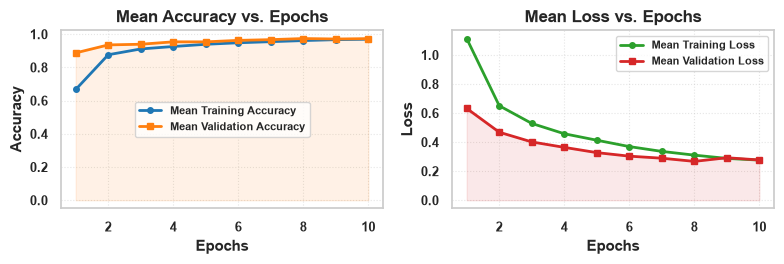

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

train_acc_all, val_acc_all, train_loss_all, val_loss_all = [], [], [], []

for seed in SEEDS:
    history = seed_outputs[seed]["history"]
    train_acc_all.append(history["train_accuracy"])
    val_acc_all.append(history["val_accuracy"])
    train_loss_all.append(history["train_loss"])
    val_loss_all.append(history["val_loss"])

train_acc_all = np.asarray(train_acc_all, dtype=float)
val_acc_all = np.asarray(val_acc_all, dtype=float)
train_loss_all = np.asarray(train_loss_all, dtype=float)
val_loss_all = np.asarray(val_loss_all, dtype=float)

mean_train_acc = np.mean(train_acc_all, axis=0)
mean_val_acc = np.mean(val_acc_all, axis=0)
mean_train_loss = np.mean(train_loss_all, axis=0)
mean_val_loss = np.mean(val_loss_all, axis=0)
epochs = np.arange(1, len(mean_train_acc) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 2.8))

ax1.plot(epochs, mean_train_acc, color="#1f77b4", linestyle="-", marker="o", markersize=4, linewidth=2, label="Mean Training Accuracy")
ax1.plot(epochs, mean_val_acc, color="#ff7f0e", linestyle="-", marker="s", markersize=4, linewidth=2, label="Mean Validation Accuracy")
ax1.fill_between(epochs, mean_val_acc, color="#ff7f0e", alpha=0.10)
ax1.set_xlabel("Epochs", fontsize=11, fontweight="bold")
ax1.set_ylabel("Accuracy", fontsize=11, fontweight="bold")
ax1.set_title("Mean Accuracy vs. Epochs", fontsize=12, fontweight="bold")
ax1.tick_params(axis="both", labelsize=9)
for tick in ax1.get_xticklabels() + ax1.get_yticklabels():
    tick.set_fontweight("bold")
ax1.legend(frameon=True, prop={"weight": "bold", "size": 8})
ax1.grid(True, linestyle=":", linewidth=0.8, alpha=0.5)

ax2.plot(epochs, mean_train_loss, color="#2ca02c", linestyle="-", marker="o", markersize=4, linewidth=2, label="Mean Training Loss")
ax2.plot(epochs, mean_val_loss, color="#d62728", linestyle="-", marker="s", markersize=4, linewidth=2, label="Mean Validation Loss")
ax2.fill_between(epochs, mean_val_loss, color="#d62728", alpha=0.10)
ax2.set_xlabel("Epochs", fontsize=11, fontweight="bold")
ax2.set_ylabel("Loss", fontsize=11, fontweight="bold")
ax2.set_title("Mean Loss vs. Epochs", fontsize=12, fontweight="bold")
ax2.tick_params(axis="both", labelsize=9)
for tick in ax2.get_xticklabels() + ax2.get_yticklabels():
    tick.set_fontweight("bold")
ax2.legend(frameon=True, prop={"weight": "bold", "size": 8})
ax2.grid(True, linestyle=":", linewidth=0.8, alpha=0.5)

plt.tight_layout()
plt.show()
plt.close(fig)


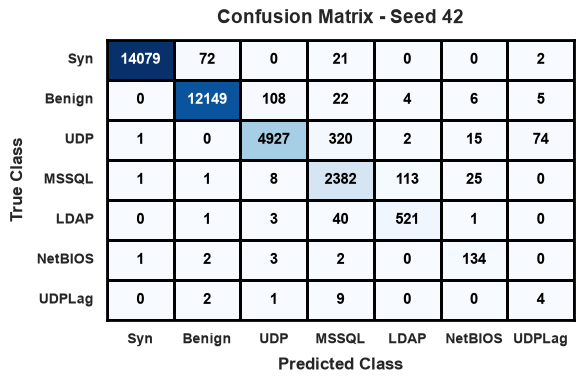

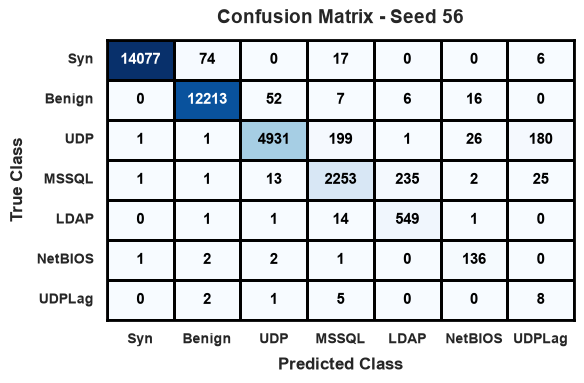

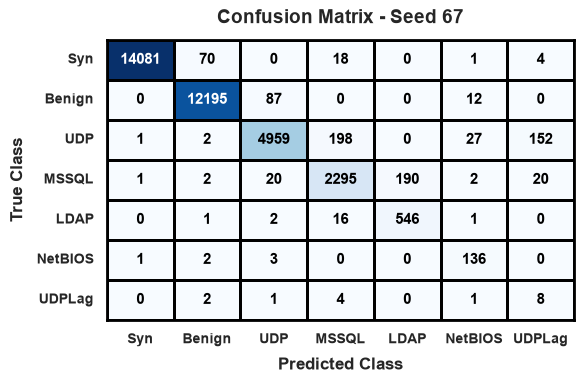

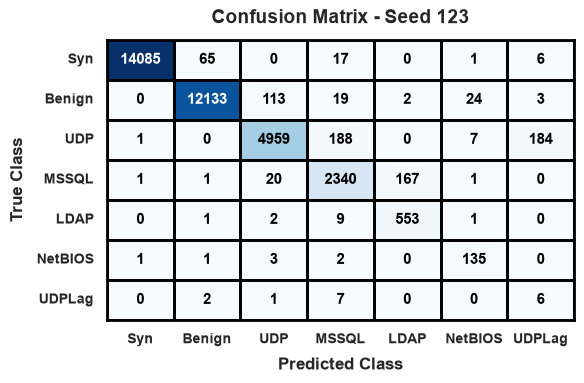

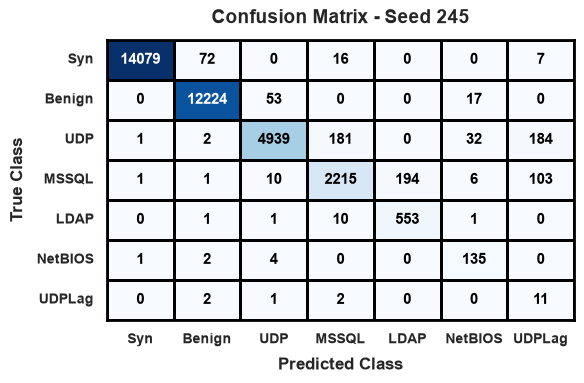

In [ ]:
for seed in SEEDS:
    output = seed_outputs[seed]
    cm_raw = confusion_matrix(output["test_true"], output["test_pred"], labels=np.arange(NUM_CLASSES))
    class_totals = cm_raw.sum(axis=1) + cm_raw.sum(axis=0)
    sorted_indices = np.argsort(class_totals)[::-1]
    cm = cm_raw[np.ix_(sorted_indices, sorted_indices)]
    sorted_class_names = [class_names[i] for i in sorted_indices]

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=False, linewidths=2, linecolor="black", xticklabels=sorted_class_names, yticklabels=sorted_class_names, annot_kws={"size": 11, "weight": "bold"}, ax=ax)

    threshold = cm.max() / 2 if cm.size else 0
    for text in ax.texts:
        try:
            value = float(text.get_text())
            text.set_fontweight("bold")
            text.set_fontsize(11)
            text.set_color("white" if value > threshold else "black")
        except ValueError:
            pass

    ax.set_title(f"Confusion Matrix - Seed {seed}", fontsize=14, fontweight="bold", pad=12)
    ax.set_xlabel("Predicted Class", fontsize=12, fontweight="bold", labelpad=8)
    ax.set_ylabel("True Class", fontsize=12, fontweight="bold", labelpad=8)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0, ha="center", fontsize=10, fontweight="bold")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, ha="right", fontsize=10, fontweight="bold")

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(2)

    plt.tight_layout()
    plt.show()
    plt.close(fig)

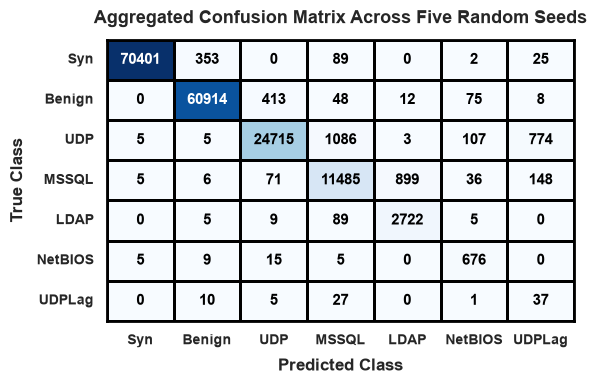

In [ ]:
cm_aggregated = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
for seed in SEEDS:
    output = seed_outputs[seed]
    cm_raw = confusion_matrix(
        output["test_true"],
        output["test_pred"],
        labels=np.arange(NUM_CLASSES))
    cm_aggregated += cm_raw
class_totals = (cm_aggregated.sum(axis=1) +cm_aggregated.sum(axis=0))
sorted_indices = np.argsort(class_totals)[::-1]
cm = cm_aggregated[np.ix_(sorted_indices, sorted_indices)]
sorted_class_names = [
    class_names[i] for i in sorted_indices]
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    square=False,
    linewidths=2,
    linecolor="black",
    xticklabels=sorted_class_names,
    yticklabels=sorted_class_names,
    annot_kws={"size": 11, "weight": "bold"},
    ax=ax)
threshold = cm.max() / 2 if cm.size else 0

for txt in ax.texts:
    try:
        value = float(txt.get_text())
        txt.set_fontweight("bold")
        txt.set_fontsize(11)
        txt.set_color("white" if value > threshold else "black")
    except ValueError:
        pass

ax.set_title(
    "Aggregated Confusion Matrix Across Five Random Seeds",
    fontsize=13,
    fontweight="bold",
    pad=12)

ax.set_xlabel(
    "Predicted Class",
    fontsize=12,
    fontweight="bold",
    labelpad=8
)

ax.set_ylabel(
    "True Class",
    fontsize=12,
    fontweight="bold",
    labelpad=8
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=0,
    ha="center",
    fontsize=10,
    fontweight="bold"
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    ha="right",
    fontsize=10,
    fontweight="bold"
)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(2)

plt.tight_layout()
plt.show()
plt.close(fig)

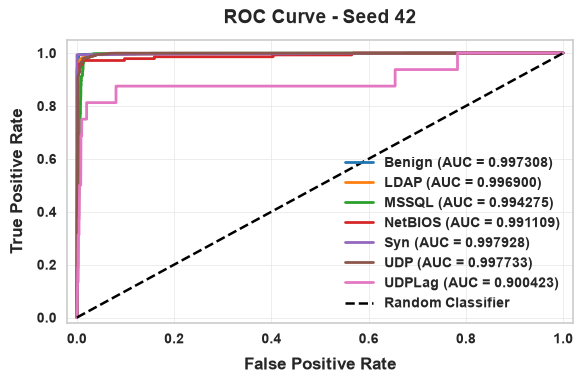

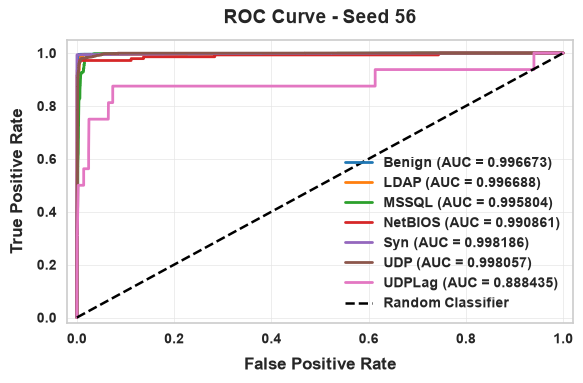

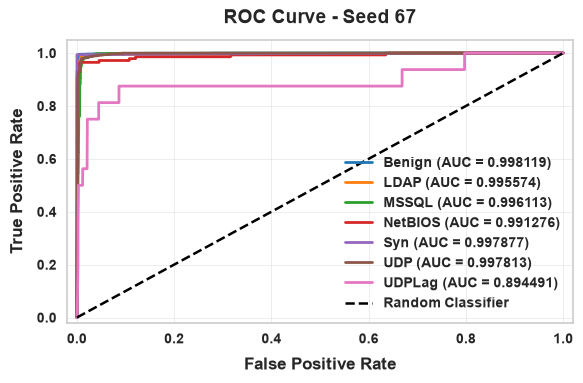

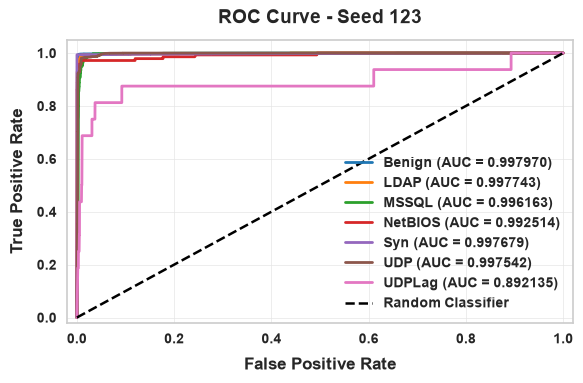

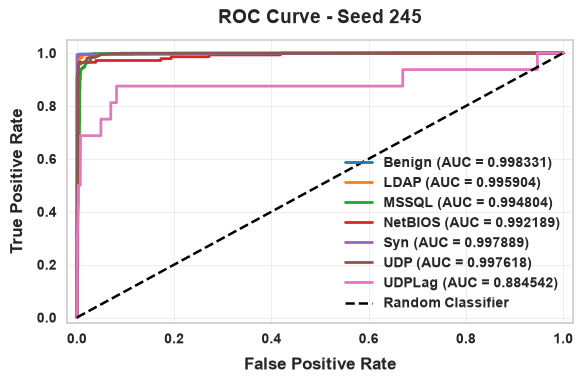

In [ ]:
ROC_COLORS = plt.cm.tab10.colors

for seed in SEEDS:
    output = seed_outputs[seed]
    yt = np.asarray(output["test_true"])
    prob = np.asarray(output["test_prob"])
    fig, ax = plt.subplots(figsize=(6, 4))

    if NUM_CLASSES == 2:
        if len(np.unique(yt)) == 2:
            fpr, tpr, _ = roc_curve(yt, prob[:, 1])
            roc_auc = auc(fpr, tpr)
            ax.plot(fpr, tpr, color=ROC_COLORS[0], linestyle="-", linewidth=2.0, label=f"Proposed Model (AUC = {roc_auc:.6f})")
    else:
        ybin = label_binarize(yt, classes=np.arange(NUM_CLASSES))
        for i, name in enumerate(class_names):
            if len(np.unique(ybin[:, i])) < 2:
                continue
            fpr, tpr, _ = roc_curve(ybin[:, i], prob[:, i])
            roc_auc = auc(fpr, tpr)
            ax.plot(fpr, tpr, color=ROC_COLORS[i % len(ROC_COLORS)], linestyle="-", linewidth=2.0, label=f"{name} (AUC = {roc_auc:.6f})")

    ax.plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=1.8, label="Random Classifier")
    ax.set_xlabel("False Positive Rate", fontsize=12, fontweight="bold", labelpad=8)
    ax.set_ylabel("True Positive Rate", fontsize=12, fontweight="bold", labelpad=8)
    ax.set_title(f"ROC Curve - Seed {seed}", fontsize=14, fontweight="bold", pad=12)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.05)
    ax.set_xticks(np.arange(0.0, 1.1, 0.2))
    ax.set_yticks(np.arange(0.0, 1.1, 0.2))
    ax.tick_params(axis="both", labelsize=10, direction="out", width=1.0, length=4)

    for tick in ax.get_xticklabels() + ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.grid(True, linestyle="-", linewidth=0.6, color="#E5E5E5", alpha=0.8)

    for spine in ax.spines.values():
        spine.set_linewidth(1.2)
        spine.set_color("#CCCCCC")

    ax.legend(loc="lower right", frameon=False, prop={"weight": "bold", "size": 10})
    plt.tight_layout()
    plt.show()
    plt.close(fig)

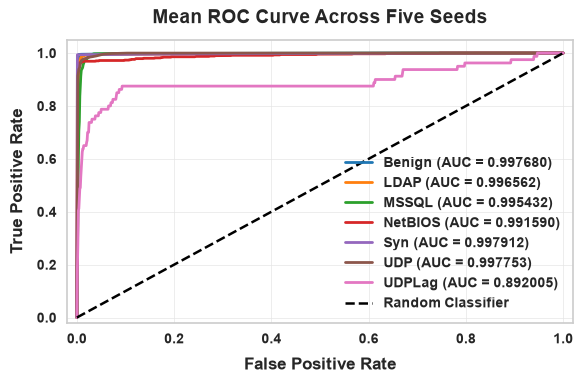

In [ ]:
ROC_COLORS = plt.cm.tab10.colors
MEAN_FPR = np.linspace(0, 1, 1000)
fig, ax = plt.subplots(figsize=(6, 4))

if NUM_CLASSES == 2:
    seed_tprs, seed_aucs = [], []
    for seed in SEEDS:
        output = seed_outputs[seed]
        yt = np.asarray(output["test_true"]).astype(int)
        prob = np.asarray(output["test_prob"])
        if len(np.unique(yt)) < 2:
            continue
        fpr, tpr, _ = roc_curve(yt, prob[:, 1])
        seed_tprs.append(np.interp(MEAN_FPR, fpr, tpr))
        seed_aucs.append(auc(fpr, tpr))
    if seed_tprs:
        mean_tpr = np.mean(seed_tprs, axis=0)
        mean_tpr[0], mean_tpr[-1] = 0.0, 1.0
        mean_auc = np.mean(seed_aucs)
        ax.plot(MEAN_FPR, mean_tpr, color=ROC_COLORS[0], linewidth=2.2, label=f"Mean ROC (AUC = {mean_auc:.6f})")
else:
    class_tprs = {i: [] for i in range(NUM_CLASSES)}
    class_aucs = {i: [] for i in range(NUM_CLASSES)}

    for seed in SEEDS:
        output = seed_outputs[seed]
        yt = np.asarray(output["test_true"]).astype(int)
        prob = np.asarray(output["test_prob"])
        ybin = label_binarize(yt, classes=np.arange(NUM_CLASSES))

        for i in range(NUM_CLASSES):
            if len(np.unique(ybin[:, i])) < 2:
                continue
            fpr, tpr, _ = roc_curve(ybin[:, i], prob[:, i])
            interpolated_tpr = np.interp(MEAN_FPR, fpr, tpr)
            interpolated_tpr[0] = 0.0
            class_tprs[i].append(interpolated_tpr)
            class_aucs[i].append(auc(fpr, tpr))

    for i, name in enumerate(class_names):
        if not class_tprs[i]:
            continue
        mean_tpr = np.mean(class_tprs[i], axis=0)
        mean_tpr[0], mean_tpr[-1] = 0.0, 1.0
        mean_auc = np.mean(class_aucs[i])
        ax.plot(MEAN_FPR, mean_tpr, color=ROC_COLORS[i % len(ROC_COLORS)], linestyle="-", linewidth=2.0, label=f"{name} (AUC = {mean_auc:.6f})")

ax.plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=1.8, label="Random Classifier")
ax.set_xlabel("False Positive Rate", fontsize=12, fontweight="bold", labelpad=8)
ax.set_ylabel("True Positive Rate", fontsize=12, fontweight="bold", labelpad=8)
ax.set_title("Mean ROC Curve Across Five Seeds", fontsize=14, fontweight="bold", pad=12)
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.05)
ax.set_xticks(np.arange(0.0, 1.1, 0.2))
ax.set_yticks(np.arange(0.0, 1.1, 0.2))
ax.tick_params(axis="both", labelsize=10, direction="out", width=1.0, length=4)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

ax.grid(True, linestyle="-", linewidth=0.6, color="#E5E5E5", alpha=0.8)

for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color("#CCCCCC")

ax.legend(loc="lower right", frameon=False, prop={"weight": "bold", "size": 10})
plt.tight_layout()
plt.show()
plt.close(fig)

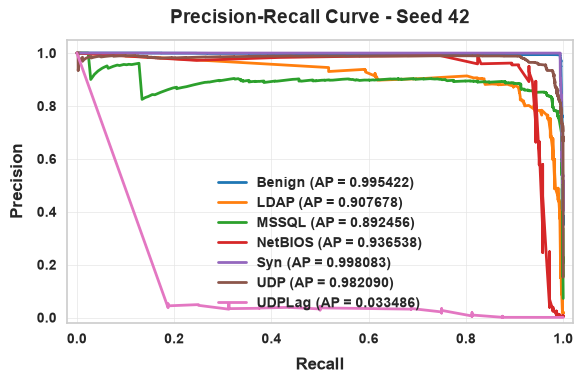

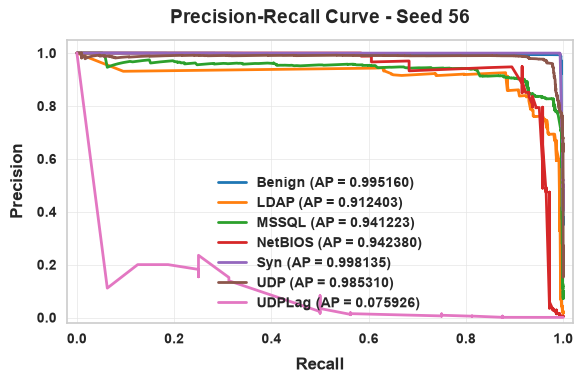

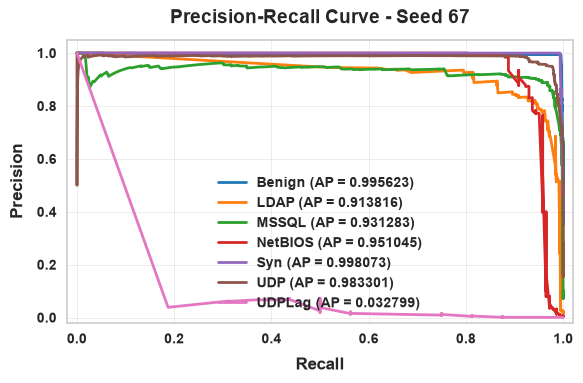

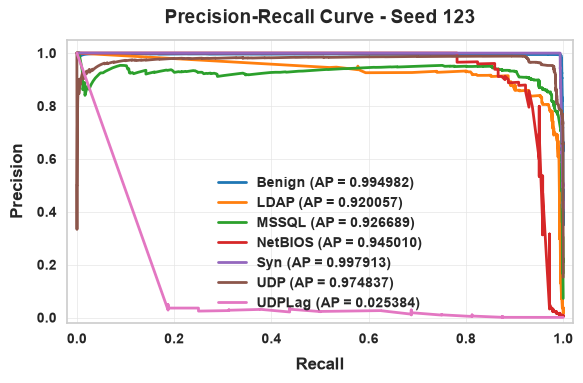

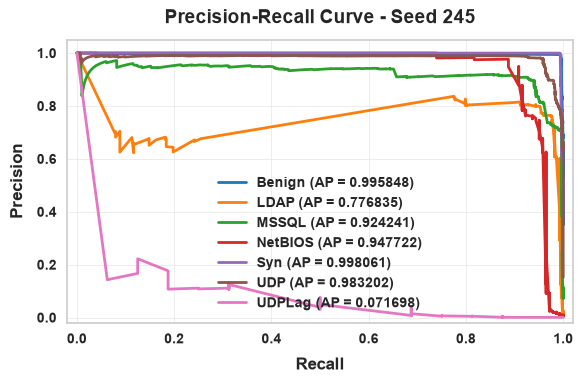

In [ ]:
PR_COLORS = plt.cm.tab10.colors

for seed in SEEDS:
    output = seed_outputs[seed]
    yt = np.asarray(output["test_true"])
    prob = np.asarray(output["test_prob"])
    fig, ax = plt.subplots(figsize=(6, 4))
    plotted = False

    if NUM_CLASSES == 2:
        if len(np.unique(yt)) == 2:
            precision_values, recall_values, _ = precision_recall_curve(yt, prob[:, 1])
            ap = average_precision_score(yt, prob[:, 1])

            sort_idx = np.argsort(recall_values)
            recall_values = recall_values[sort_idx]
            precision_values = precision_values[sort_idx]

            ax.plot(recall_values, precision_values, color=PR_COLORS[0], linestyle="-", linewidth=2.0, label=f"Average Precision (AP = {ap:.6f})")
            plotted = True
    else:
        ybin = label_binarize(yt, classes=np.arange(NUM_CLASSES))
        for i, name in enumerate(class_names):
            if len(np.unique(ybin[:, i])) < 2:
                continue
            precision_values, recall_values, _ = precision_recall_curve(ybin[:, i], prob[:, i])
            ap = average_precision_score(ybin[:, i], prob[:, i])

            sort_idx = np.argsort(recall_values)
            recall_values = recall_values[sort_idx]
            precision_values = precision_values[sort_idx]

            if name in ["LDAP", "UDPLag"]:
                valid_idx = ~((recall_values < 0.03) & (precision_values < 0.9))
                recall_values = recall_values[valid_idx]
                precision_values = precision_values[valid_idx]
            else:
                valid_idx = (recall_values > 0) | (precision_values > 0)
                recall_values = recall_values[valid_idx]
                precision_values = precision_values[valid_idx]

            ax.plot(recall_values, precision_values, color=PR_COLORS[i % len(PR_COLORS)], linestyle="-", linewidth=2.0, label=f"{name} (AP = {ap:.6f})")
            plotted = True

    ax.set_xlabel("Recall", fontsize=12, fontweight="bold", labelpad=8)
    ax.set_ylabel("Precision", fontsize=12, fontweight="bold", labelpad=8)
    ax.set_title(f"Precision-Recall Curve - Seed {seed}", fontsize=14, fontweight="bold", pad=12)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.05)
    ax.set_xticks(np.arange(0.0, 1.1, 0.2))
    ax.set_yticks(np.arange(0.0, 1.1, 0.2))
    ax.tick_params(axis="both", labelsize=10, direction="out", width=1.0, length=4)

    for tick in ax.get_xticklabels() + ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.grid(True, linestyle="-", linewidth=0.6, color="#E5E5E5", alpha=0.8)

    for spine in ax.spines.values():
        spine.set_linewidth(1.2)
        spine.set_color("#CCCCCC")

    if plotted:
        ax.legend(loc="lower center", frameon=False, prop={"weight": "bold", "size": 10})

    plt.tight_layout()
    plt.show()
    plt.close(fig)

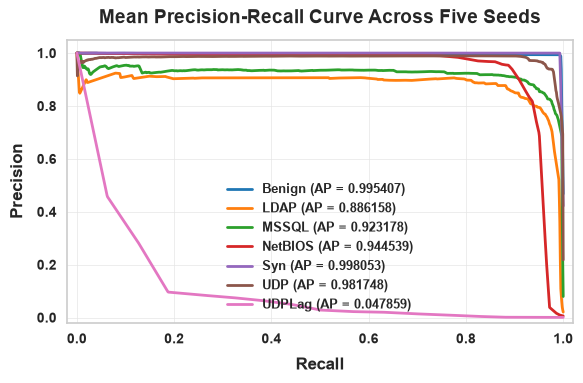

In [ ]:
PR_COLORS = plt.cm.tab10.colors
MEAN_RECALL = np.linspace(0, 1, 1000)
fig, ax = plt.subplots(figsize=(6, 4))
plotted = False

if NUM_CLASSES == 2:
    seed_precisions, seed_aps = [], []
    for seed in SEEDS:
        output = seed_outputs[seed]
        yt, prob = np.asarray(output["test_true"]).astype(int), np.asarray(output["test_prob"])
        if len(np.unique(yt)) < 2:
            continue
        precision, recall, _ = precision_recall_curve(yt, prob[:, 1])
        ap = average_precision_score(yt, prob[:, 1])
        sort_idx = np.argsort(recall)
        recall_sorted, precision_sorted = recall[sort_idx], precision[sort_idx]
        unique_recall, unique_idx = np.unique(recall_sorted, return_index=True)
        interpolated_precision = np.interp(MEAN_RECALL, unique_recall, precision_sorted[unique_idx])
        seed_precisions.append(interpolated_precision)
        seed_aps.append(ap)
    if seed_precisions:
        ax.plot(MEAN_RECALL, np.mean(seed_precisions, axis=0), color=PR_COLORS[0], linewidth=2.2, label=f"Mean PR Curve (AP = {np.mean(seed_aps):.6f})")
        plotted = True
else:
    class_precisions, class_aps = {i: [] for i in range(NUM_CLASSES)}, {i: [] for i in range(NUM_CLASSES)}
    for seed in SEEDS:
        output = seed_outputs[seed]
        yt, prob = np.asarray(output["test_true"]).astype(int), np.asarray(output["test_prob"])
        ybin = label_binarize(yt, classes=np.arange(NUM_CLASSES))
        for i in range(NUM_CLASSES):
            if len(np.unique(ybin[:, i])) < 2:
                continue
            precision, recall, _ = precision_recall_curve(ybin[:, i], prob[:, i])
            ap = average_precision_score(ybin[:, i], prob[:, i])
            sort_idx = np.argsort(recall)
            recall_sorted, precision_sorted = recall[sort_idx], precision[sort_idx]
            unique_recall, unique_idx = np.unique(recall_sorted, return_index=True)
            interpolated_precision = np.interp(MEAN_RECALL, unique_recall, precision_sorted[unique_idx])
            class_precisions[i].append(interpolated_precision)
            class_aps[i].append(ap)
    for i, name in enumerate(class_names):
        if not class_precisions[i]:
            continue
        ax.plot(MEAN_RECALL, np.mean(class_precisions[i], axis=0), color=PR_COLORS[i % len(PR_COLORS)], linewidth=2.0, label=f"{name} (AP = {np.mean(class_aps[i]):.6f})")
        plotted = True

ax.set_xlabel("Recall", fontsize=12, fontweight="bold", labelpad=8)
ax.set_ylabel("Precision", fontsize=12, fontweight="bold", labelpad=8)
ax.set_title("Mean Precision-Recall Curve Across Five Seeds", fontsize=14, fontweight="bold", pad=12)
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.05)
ax.set_xticks(np.arange(0.0, 1.1, 0.2))
ax.set_yticks(np.arange(0.0, 1.1, 0.2))
ax.tick_params(axis="both", labelsize=10, direction="out", width=1.0, length=4)
for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")
ax.grid(True, linestyle="-", linewidth=0.6, color="#E5E5E5", alpha=0.8)
for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color("#CCCCCC")
if plotted:
    ax.legend(loc="lower center",frameon=False,prop={"weight": "bold", "size": 9},ncol=1)
else:
    print("PR curve could not be generated.")
plt.tight_layout()
plt.show()
plt.close(fig)

In [ ]:
metric_columns=["Accuracy","Precision (Macro)","Precision (Weighted)","Recall (Macro)","Recall (Weighted)","F1-Score (Macro)","F1-Score (Weighted)","Specificity (Macro)","Specificity (Weighted)","ROC-AUC (Macro)","ROC-AUC (Weighted)","MCC (Multiclass)","MCC (Macro OvR)","MCC (Weighted OvR)","Cohen's Kappa"]
metric_results=[]
for seed in SEEDS:
    output=seed_outputs[seed]
    yt=np.asarray(output["test_true"])
    yp=np.asarray(output["test_pred"])
    prob=np.asarray(output["test_prob"])
    cm=confusion_matrix(yt,yp,labels=np.arange(NUM_CLASSES))
    tp=np.diag(cm).astype(float)
    fp=cm.sum(axis=0)-tp
    fn=cm.sum(axis=1)-tp
    tn=cm.sum()-tp-fp-fn
    support=cm.sum(axis=1).astype(float)
    spec=np.divide(tn,tn+fp,out=np.zeros_like(tn),where=(tn+fp)!=0)
    ybin=label_binarize(yt,classes=np.arange(NUM_CLASSES))
    auc_cls=np.array([roc_auc_score(ybin[:,i],prob[:,i]) if len(np.unique(ybin[:,i]))==2 else np.nan for i in range(NUM_CLASSES)])
    valid=np.isfinite(auc_cls)
    mcc_cls=np.array([matthews_corrcoef((yt==i).astype(int),(yp==i).astype(int)) for i in range(NUM_CLASSES)])
    metric_results.append({"Seed":seed,"Accuracy":accuracy_score(yt,yp),"Precision (Macro)":precision_score(yt,yp,average="macro",zero_division=0),"Precision (Weighted)":precision_score(yt,yp,average="weighted",zero_division=0),"Recall (Macro)":recall_score(yt,yp,average="macro",zero_division=0),"Recall (Weighted)":recall_score(yt,yp,average="weighted",zero_division=0),"F1-Score (Macro)":f1_score(yt,yp,average="macro",zero_division=0),"F1-Score (Weighted)":f1_score(yt,yp,average="weighted",zero_division=0),"Specificity (Macro)":np.mean(spec),"Specificity (Weighted)":np.average(spec,weights=support),"ROC-AUC (Macro)":np.mean(auc_cls[valid]) if valid.any() else np.nan,"ROC-AUC (Weighted)":np.average(auc_cls[valid],weights=support[valid]) if valid.any() and support[valid].sum()>0 else np.nan,"MCC (Multiclass)":matthews_corrcoef(yt,yp),"MCC (Macro OvR)":np.mean(mcc_cls),"MCC (Weighted OvR)":np.average(mcc_cls,weights=support),"Cohen's Kappa":cohen_kappa_score(yt,yp)})
metrics_df=pd.DataFrame(metric_results).set_index("Seed")
summary_rows=[]
n=len(metrics_df)
for metric in metric_columns:
    values=pd.to_numeric(metrics_df[metric],errors="coerce").dropna().to_numpy()
    count=len(values)
    mean=np.mean(values) if count else np.nan
    sd=np.std(values,ddof=1) if count>1 else np.nan
    margin=t.ppf(0.975,df=count-1)*sd/np.sqrt(count) if count>1 else np.nan
    summary_rows.append({"Metric":metric,"Mean":mean,"SD":sd,"95% CI Lower":mean-margin if count>1 else np.nan,"95% CI Upper":mean+margin if count>1 else np.nan})
summary_df=pd.DataFrame(summary_rows)
print("HYBRIDQBiDR_NALT - FIVE-SEED PERFORMANCE SUMMARY")
display(summary_df.style.format({"Mean":"{:.4f}","SD":"{:.4f}","95% CI Lower":"{:.4f}","95% CI Upper":"{:.4f}"}).hide(axis="index"))


HYBRIDQBiDR_NALT - FIVE-SEED PERFORMANCE SUMMARY


Metric,Mean,SD,95% CI Lower,95% CI Upper
Accuracy,0.9752,0.0008,0.9742,0.9761
Precision (Macro),0.7728,0.0059,0.7655,0.7802
Precision (Weighted),0.9817,0.0017,0.9795,0.9838
Recall (Macro),0.8849,0.0232,0.8561,0.9137
Recall (Weighted),0.9752,0.0008,0.9742,0.9761
F1-Score (Macro),0.7992,0.0048,0.7933,0.8051
F1-Score (Weighted),0.9779,0.0008,0.9769,0.9788
Specificity (Macro),0.9961,0.0001,0.9960,0.9962
Specificity (Weighted),0.9975,0.0003,0.9972,0.9978
ROC-AUC (Macro),0.9813,0.0008,0.9802,0.9823


In [ ]:
from sklearn.metrics import matthews_corrcoef,cohen_kappa_score,confusion_matrix,roc_auc_score
metric_results=[]
for seed in SEEDS:
    output=seed_outputs[seed]
    yt=output["test_true"]
    yp=output["test_pred"]
    prob=output["test_prob"]
    cm=confusion_matrix(yt,yp,labels=np.arange(NUM_CLASSES))
    tp=np.diag(cm).astype(float)
    fp=cm.sum(axis=0)-tp
    fn=cm.sum(axis=1)-tp
    tn=cm.sum()-tp-fp-fn
    specificity_per_class=np.divide(tn,tn+fp,out=np.zeros_like(tn),where=(tn+fp)!=0)
    support=cm.sum(axis=1).astype(float)
    total_support=support.sum()
    specificity_macro=np.mean(specificity_per_class)
    specificity_weighted=np.average(specificity_per_class,weights=support) if total_support>0 else 0.0
    ybin=label_binarize(yt,classes=np.arange(NUM_CLASSES))
    auc_per_class=[]
    for i in range(NUM_CLASSES):
        if len(np.unique(ybin[:,i]))<2:
            auc_per_class.append(np.nan)
        else:
            auc_per_class.append(roc_auc_score(ybin[:,i],prob[:,i]))
    auc_per_class=np.asarray(auc_per_class,dtype=float)
    valid_auc=np.isfinite(auc_per_class)
    roc_auc_macro=float(np.mean(auc_per_class[valid_auc])) if valid_auc.any() else np.nan
    valid_weights=support[valid_auc]
    roc_auc_weighted=float(np.average(auc_per_class[valid_auc],weights=valid_weights)) if valid_auc.any() and valid_weights.sum()>0 else np.nan
    mcc_ovr=[]
    for i in range(NUM_CLASSES):
        true_binary=(yt==i).astype(int)
        pred_binary=(yp==i).astype(int)
        mcc_ovr.append(matthews_corrcoef(true_binary,pred_binary))
    mcc_ovr=np.asarray(mcc_ovr,dtype=float)
    metrics={"Seed":seed,"Accuracy":accuracy_score(yt,yp),"Precision (Macro)":precision_score(yt,yp,average="macro",zero_division=0),"Precision (Weighted)":precision_score(yt,yp,average="weighted",zero_division=0),"Recall (Macro)":recall_score(yt,yp,average="macro",zero_division=0),"Recall (Weighted)":recall_score(yt,yp,average="weighted",zero_division=0),"F1-Score (Macro)":f1_score(yt,yp,average="macro",zero_division=0),"F1-Score (Weighted)":f1_score(yt,yp,average="weighted",zero_division=0),"Specificity (Macro)":specificity_macro,"Specificity (Weighted)":specificity_weighted,"ROC-AUC (Macro)":roc_auc_macro,"ROC-AUC (Weighted)":roc_auc_weighted,"MCC (Multiclass)":matthews_corrcoef(yt,yp),"MCC (Macro OvR)":float(np.mean(mcc_ovr)),"MCC (Weighted OvR)":float(np.average(mcc_ovr,weights=support)) if support.sum()>0 else np.nan,"Cohen's Kappa":cohen_kappa_score(yt,yp)}
    metric_results.append(metrics)
metrics_df=pd.DataFrame(metric_results).set_index("Seed")
print("HYBRIDQBiDR_NALT - ALL REQUESTED TEST METRICS")
display(metrics_df.style.format("{:.6f}"))
summary_df=pd.DataFrame({"Metric":metrics_df.columns,"Mean":[metrics_df[c].mean() for c in metrics_df.columns],"Standard Deviation":[metrics_df[c].std(ddof=1) for c in metrics_df.columns]})

print("FIVE-SEED SUMMARY")

display(summary_df.style.format({"Mean":"{:.6f}","Standard Deviation":"{:.6f}"}))


HYBRIDQBiDR_NALT - ALL REQUESTED TEST METRICS


,Accuracy,Precision (Macro),Precision (Weighted),Recall (Macro),Recall (Weighted),F1-Score (Macro),F1-Score (Weighted),Specificity (Macro),Specificity (Weighted),ROC-AUC (Macro),ROC-AUC (Weighted),MCC (Multiclass),MCC (Macro OvR),MCC (Weighted OvR),Cohen's Kappa
Seed,,,,,,,,,,,,,,,
42,0.975329,0.774634,0.978795,0.851428,0.975329,0.800480,0.976648,0.996066,0.997130,0.982239,0.997328,0.964214,0.801917,0.972203,0.964106
56,0.974502,0.766287,0.982091,0.889768,0.974502,0.794229,0.977622,0.996026,0.997681,0.980672,0.997360,0.963040,0.802556,0.973916,0.962909
67,0.976013,0.774101,0.981942,0.891962,0.976013,0.801767,0.978507,0.996220,0.997526,0.981609,0.997714,0.965182,0.809602,0.974627,0.965098
123,0.975757,0.781136,0.981951,0.876727,0.975757,0.805108,0.978461,0.996184,0.997529,0.981678,0.997583,0.964832,0.809935,0.974160,0.964747
245,0.974188,0.768065,0.983494,0.914773,0.974188,0.794432,0.978188,0.995997,0.997792,0.980182,0.997673,0.962600,0.805950,0.974599,0.962453


FIVE-SEED SUMMARY


,Metric,Mean,Standard Deviation
0,Accuracy,0.975158,0.000789
1,Precision (Macro),0.772845,0.005903
2,Precision (Weighted),0.981655,0.001726
3,Recall (Macro),0.884932,0.023201
4,Recall (Weighted),0.975158,0.000789
5,F1-Score (Macro),0.799203,0.004759
6,F1-Score (Weighted),0.977885,0.000776
7,Specificity (Macro),0.996098,0.000098
8,Specificity (Weighted),0.997532,0.000251
9,ROC-AUC (Macro),0.981276,0.000831


  0%|          | 0/100 [00:00<?, ?it/s]

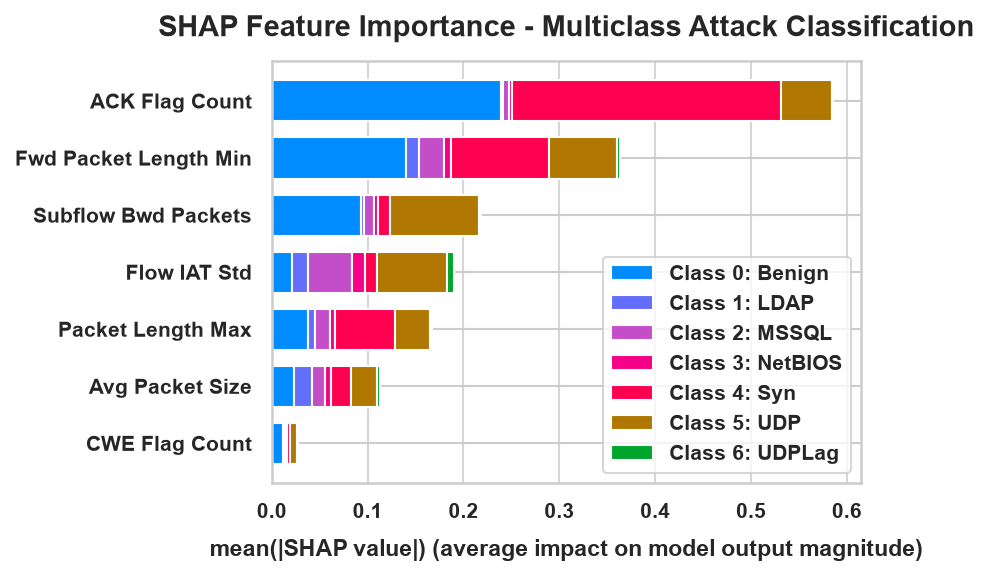

SHAP Model Seed: 42
Explained Test Samples: 100
Actual Feature Names Used: 7
Top Features Displayed: 7


,Class 0: Benign,Class 1: LDAP,Class 2: MSSQL,Class 3: NetBIOS,Class 4: Syn,Class 5: UDP,Class 6: UDPLag,Overall Importance
Feature,,,,,,,,
ACK Flag Count,0.238656,0.002456,0.006638,0.002469,0.281371,0.052397,0.001480,0.083638
Fwd Packet Length Min,0.139523,0.014386,0.026048,0.007136,0.101973,0.070586,0.003125,0.051825
Subflow Bwd Packets,0.093356,0.003143,0.009665,0.004649,0.013022,0.092487,0.001777,0.031157
Flow IAT Std,0.021558,0.015857,0.046179,0.013241,0.012593,0.073771,0.006823,0.027146
Packet Length Max,0.038080,0.006559,0.015578,0.005987,0.062277,0.036586,0.001794,0.023837
Avg Packet Size,0.023414,0.018194,0.013730,0.005958,0.021593,0.027254,0.002978,0.016160
CWE Flag Count,0.011880,0.000719,0.002044,0.001110,0.003583,0.007210,0.000428,0.003853


In [ ]:
import shap

SEED_FOR_SHAP = SEEDS[0]
SHAP_BACKGROUND_SIZE = 50
SHAP_EXPLAIN_SIZE = 100
SHAP_TOP_FEATURES = 20
SHAP_NSAMPLES = 100

if isinstance(X_train_MAO, pd.DataFrame):
    feature_names = X_train_MAO.columns.astype(str).tolist()
elif "selected_features" in globals() and len(selected_features) == X_train_np.shape[1] and all(isinstance(f, str) for f in selected_features):
    feature_names = list(selected_features)
elif "selected_feature_names" in globals() and len(selected_feature_names) == X_train_np.shape[1]:
    feature_names = [str(f) for f in selected_feature_names]
elif "feature_names" in globals() and len(feature_names) == X_train_np.shape[1]:
    feature_names = [str(f) for f in feature_names]
elif "selected_indices" in globals() and "original_feature_names" in globals() and len(selected_indices) == X_train_np.shape[1]:
    feature_names = [str(original_feature_names[i]) for i in selected_indices]
else:
    raise ValueError("Actual selected feature names are unavailable. Preserve original_feature_names before MAO selection and selected_indices from MAO.")

if len(feature_names) != INPUT_DIM:
    raise ValueError(f"Feature-name count ({len(feature_names)}) does not match model input dimension ({INPUT_DIM}).")

shap_model = HYBRIDQBiDR_NALT(INPUT_DIM, NUM_CLASSES, D_MODEL, NUM_HEADS, NUM_TRANSFORMER_LAYERS, GRU_HIDDEN, DROPOUT).to(DEVICE)
shap_model.load_state_dict(seed_outputs[SEED_FOR_SHAP]["model_state"])
shap_model.eval()

rng = np.random.default_rng(42)
background_indices = rng.choice(len(X_train_np), size=min(SHAP_BACKGROUND_SIZE, len(X_train_np)), replace=False)
explain_indices = rng.choice(len(X_test_np), size=min(SHAP_EXPLAIN_SIZE, len(X_test_np)), replace=False)
background = X_train_np[background_indices]
X_explain = X_test_np[explain_indices]

def predict_probabilities(data):
    data = np.asarray(data, dtype=np.float32)
    outputs = []
    with torch.no_grad():
        for start in range(0, len(data), 64):
            batch = torch.as_tensor(data[start:start+64], dtype=torch.float32, device=DEVICE)
            outputs.append(torch.softmax(shap_model(batch), dim=1).cpu().numpy())
    return np.concatenate(outputs, axis=0)

explainer = shap.KernelExplainer(predict_probabilities, background)
shap_raw = explainer.shap_values(X_explain, nsamples=SHAP_NSAMPLES)

if isinstance(shap_raw, list):
    shap_by_class = [np.asarray(v) for v in shap_raw]
    shap_importance = np.stack([np.mean(np.abs(v), axis=0) for v in shap_by_class], axis=1)
else:
    shap_array = np.asarray(shap_raw)
    if shap_array.ndim == 3 and shap_array.shape[0] == len(X_explain) and shap_array.shape[1] == len(feature_names):
        shap_importance = np.mean(np.abs(shap_array), axis=0)
    elif shap_array.ndim == 3 and shap_array.shape[0] == len(X_explain) and shap_array.shape[2] == len(feature_names):
        shap_importance = np.mean(np.abs(shap_array), axis=0).T
    else:
        raise ValueError(f"Unexpected SHAP output shape: {shap_array.shape}")

if shap_importance.shape != (len(feature_names), NUM_CLASSES):
    raise ValueError(f"SHAP shape {shap_importance.shape} does not match ({len(feature_names)}, {NUM_CLASSES}). Check SHAP output dimensions and class count.")

importance_df = pd.DataFrame(shap_importance, index=feature_names, columns=[f"Class {i}: {name}" for i, name in enumerate(class_names)])
importance_df.index.name = "Feature"
importance_df["Overall Importance"] = importance_df.mean(axis=1)
top_names = importance_df.nlargest(min(SHAP_TOP_FEATURES, len(feature_names)), "Overall Importance").sort_values("Overall Importance").index
top_features = importance_df.loc[top_names].drop(columns="Overall Importance")

plt.rcParams.update({"font.weight": "bold", "axes.titleweight": "bold", "axes.labelweight": "bold", "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 11})

fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
class_colors = ["#008BFF", "#636EFA", "#C44ECA", "#F50087", "#FF0050", "#B07800", "#00A52B", "#009DB8"]
left = np.zeros(len(top_features))

for i, col in enumerate(top_features.columns):
    values = top_features[col].to_numpy()
    ax.barh(top_features.index, values, left=left, color=class_colors[i % len(class_colors)], label=col, height=0.72)
    left += values

ax.set_title("SHAP Feature Importance - Multiclass Attack Classification", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("mean(|SHAP value|) (average impact on model output magnitude)", fontsize=11, fontweight="bold", labelpad=8)
ax.set_ylabel("", fontweight="bold")
ax.tick_params(axis="both", labelsize=10)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

ax.grid(axis="x", color="#CCCCCC", linewidth=1, alpha=0.8)
ax.set_axisbelow(True)

legend = ax.legend(loc="lower right", fontsize=10, frameon=True, facecolor="white", edgecolor="#CCCCCC", prop={"weight": "bold", "size": 10})
for text in legend.get_texts():
    text.set_fontweight("bold")

for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color("#CCCCCC")

plt.tight_layout()
plt.show()
plt.close(fig)

print(f"SHAP Model Seed: {SEED_FOR_SHAP}")
print(f"Explained Test Samples: {len(X_explain)}")
print(f"Actual Feature Names Used: {len(feature_names)}")
print(f"Top Features Displayed: {len(top_features)}")
display(importance_df.sort_values("Overall Importance", ascending=False).style.set_properties(**{"font-weight": "bold"}).set_table_styles([{"selector": "th", "props": [("font-weight", "bold")]}]))

In [ ]:
import io
from torch.utils.data import DataLoader

BENCHMARK_BATCH_SIZE = 64
WARMUP_STEPS = 5
LATENCY_RUNS = 100
benchmark_device = DEVICE

def synchronize_device():
    if benchmark_device.type == "cuda":
        torch.cuda.synchronize(benchmark_device)

benchmark_model = HYBRIDQBiDR_NALT(INPUT_DIM, NUM_CLASSES, D_MODEL, NUM_HEADS, NUM_TRANSFORMER_LAYERS, GRU_HIDDEN, DROPOUT).to(benchmark_device)
last_seed = SEEDS[-1]
benchmark_model.load_state_dict(seed_outputs[last_seed]["model_state"])
benchmark_model.eval()

total_params = sum(p.numel() for p in benchmark_model.parameters())
trainable_params = sum(p.numel() for p in benchmark_model.parameters() if p.requires_grad)
non_trainable_params = total_params - trainable_params
parameter_bytes = sum(p.numel() * p.element_size() for p in benchmark_model.parameters())
buffer_bytes = sum(b.numel() * b.element_size() for b in benchmark_model.buffers())
model_size_mb = (parameter_bytes + buffer_bytes) / (1024 ** 2)

checkpoint_buffer = io.BytesIO()
torch.save(benchmark_model.state_dict(), checkpoint_buffer)
checkpoint_size_mb = len(checkpoint_buffer.getvalue()) / (1024 ** 2)

print("MODEL PARAMETER DETAILS")
print(f"Total Parameters       : {total_params:,}")
print(f"Trainable Parameters   : {trainable_params:,}")
print(f"Non-trainable Params   : {non_trainable_params:,}")
print(f"Model Weights Size     : {model_size_mb:.4f} MB")
print(f"Serialized State Size  : {checkpoint_size_mb:.4f} MB")
print(f"Parameter Memory       : {parameter_bytes / (1024**2):.4f} MB")
print(f"Benchmark Device       : {benchmark_device}")

macs, flops = np.nan, np.nan
flops_method = "Unavailable"
sample_input = torch.zeros(1, INPUT_DIM, dtype=torch.float32, device=benchmark_device)

try:
    from thop import profile
    macs, _ = profile(benchmark_model, inputs=(sample_input,), verbose=False)
    flops = 2 * macs
    flops_method = "THOP"
except ImportError:
    try:
        from torch.profiler import profile as torch_profile, ProfilerActivity
        activities = [ProfilerActivity.CPU]
        if benchmark_device.type == "cuda":
            activities.append(ProfilerActivity.CUDA)
        with torch.inference_mode():
            with torch_profile(activities=activities, record_shapes=True, with_flops=True) as prof:
                benchmark_model(sample_input)
        flops = sum(event.flops or 0 for event in prof.key_averages())
        flops_method = "PyTorch profiler (supported ops only)"
    except Exception as e:
        print("FLOPs estimation unavailable:", str(e))

print("COMPUTATIONAL COMPLEXITY: ONE SAMPLE")
if np.isfinite(flops):
    print(f"FLOPs                : {flops:,.0f}")
    print(f"FLOPs (Millions)     : {flops / 1e6:.6f} MFLOPs")
    print(f"FLOPs (Billions)     : {flops / 1e9:.8f} GFLOPs")
    print(f"MACs                 : {macs:,.0f}" if np.isfinite(macs) else "MACs                 : Not independently measured")
    print(f"Counting Method      : {flops_method}")
else:
    print("FLOPs could not be measured. Install THOP using: pip install thop")

training_rows = []
for seed in SEEDS:
    out = seed_outputs[seed]
    elapsed = out["training_time"]
    epochs_completed = len(out["history"]["train_loss"])
    training_rows.append({
        "Seed": seed,
        "Epochs_Completed": epochs_completed,
        "Training_Time_Seconds": elapsed,
        "Training_Time_Minutes": elapsed / 60,
        "Average_Time_Per_Epoch_Seconds": elapsed / max(epochs_completed, 1),
        "Best_Epoch": out["best_epoch"],
        "Best_Validation_Loss": out["best_val_loss"]
    })

training_time_df = pd.DataFrame(training_rows)
print("FIVE-SEED TRAINING TIME")
display(training_time_df)
print(f"Total Five-Seed Training Time: {training_time_df['Training_Time_Seconds'].sum():.2f} seconds")
print(f"Average Training Time/Seed  : {training_time_df['Training_Time_Seconds'].mean():.2f} seconds")

inference_loader = DataLoader(test_dataset, batch_size=BENCHMARK_BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=(benchmark_device.type == "cuda"))

with torch.inference_mode():
    for i, (bx, _) in enumerate(inference_loader):
        _ = benchmark_model(bx.to(benchmark_device))
        if i + 1 >= WARMUP_STEPS:
            break

synchronize_device()
inference_start = time.perf_counter()
inference_samples, inference_batches = 0, 0

with torch.inference_mode():
    for bx, _ in inference_loader:
        bx = bx.to(benchmark_device)
        _ = benchmark_model(bx)
        inference_samples += bx.shape[0]
        inference_batches += 1

synchronize_device()
inference_total_seconds = time.perf_counter() - inference_start
inference_seconds_per_sample = inference_total_seconds / max(inference_samples, 1)
inference_ms_per_sample = inference_seconds_per_sample * 1000
throughput_samples_sec = inference_samples / max(inference_total_seconds, 1e-12)
inference_ms_per_batch = inference_total_seconds / max(inference_batches, 1) * 1000

single_input = X_test_tensor[:1].to(benchmark_device)
with torch.inference_mode():
    for _ in range(WARMUP_STEPS):
        _ = benchmark_model(single_input)

synchronize_device()
latency_times = []
with torch.inference_mode():
    for _ in range(LATENCY_RUNS):
        synchronize_device()
        t0 = time.perf_counter()
        _ = benchmark_model(single_input)
        synchronize_device()
        latency_times.append(time.perf_counter() - t0)

latency_ms_mean = np.mean(latency_times) * 1000
latency_ms_median = np.median(latency_times) * 1000
latency_ms_p95 = np.percentile(latency_times, 95) * 1000

print("INFERENCE PERFORMANCE")
print(f"Test Samples Processed      : {inference_samples:,}")
print(f"Inference Batch Size        : {BENCHMARK_BATCH_SIZE}")
print(f"Total Inference Time        : {inference_total_seconds:.4f} seconds")
print(f"Total Inference Time        : {inference_total_seconds / 60:.4f} minutes")
print(f"Average Time per Sample     : {inference_ms_per_sample:.6f} ms")
print(f"Average Time per Batch      : {inference_ms_per_batch:.4f} ms")
print(f"Throughput                  : {throughput_samples_sec:.2f} samples/sec")
print(f"Single-Sample Mean Latency  : {latency_ms_mean:.6f} ms")
print(f"Single-Sample Median Latency: {latency_ms_median:.6f} ms")
print(f"Single-Sample P95 Latency   : {latency_ms_p95:.6f} ms")

complexity_df = pd.DataFrame([{
    "Model": "HYBRIDQBiDR_NALT",
    "Input_Features": INPUT_DIM,
    "Classes": NUM_CLASSES,
    "Total_Parameters": total_params,
    "Trainable_Parameters": trainable_params,
    "Nontrainable_Parameters": non_trainable_params,
    "Model_Weights_MB": model_size_mb,
    "Serialized_State_MB": checkpoint_size_mb,
    "FLOPs_Per_Sample": flops,
    "MFLOPs_Per_Sample": flops / 1e6 if np.isfinite(flops) else np.nan,
    "GFLOPs_Per_Sample": flops / 1e9 if np.isfinite(flops) else np.nan,
    "MACs_Per_Sample": macs,
    "FLOPs_Method": flops_method,
    "Five_Seed_Training_Time_Sec": training_time_df["Training_Time_Seconds"].sum(),
    "Mean_Training_Time_Per_Seed_Sec": training_time_df["Training_Time_Seconds"].mean(),
    "Test_Inference_Time_Sec": inference_total_seconds,
    "Inference_Time_Per_Sample_ms": inference_ms_per_sample,
    "Single_Sample_Mean_Latency_ms": latency_ms_mean,
    "Single_Sample_Median_Latency_ms": latency_ms_median,
    "Single_Sample_P95_Latency_ms": latency_ms_p95,
    "Inference_Throughput_Samples_Sec": throughput_samples_sec
}])

print("FINAL MODEL COMPLEXITY SUMMARY")
display(complexity_df.T.rename(columns={0: "Value"}))

MODEL PARAMETER DETAILS
Total Parameters       : 179,143
Trainable Parameters   : 179,143
Non-trainable Params   : 0
Model Weights Size     : 0.6834 MB
Serialized State Size  : 0.7048 MB
Parameter Memory       : 0.6834 MB
Benchmark Device       : cpu
COMPUTATIONAL COMPLEXITY: ONE SAMPLE
FLOPs                : 1,317,888
FLOPs (Millions)     : 1.317888 MFLOPs
FLOPs (Billions)     : 0.00131789 GFLOPs
MACs                 : 658,944
Counting Method      : THOP
FIVE-SEED TRAINING TIME


,Seed,Epochs_Completed,Training_Time_Seconds,Training_Time_Minutes,Average_Time_Per_Epoch_Seconds,Best_Epoch,Best_Validation_Loss
0,42,10,256.210843,4.270181,25.621084,9,0.261906
1,56,10,262.278236,4.371304,26.227824,10,0.254169
2,67,10,260.731178,4.345520,26.073118,9,0.242326
3,123,10,261.605227,4.360087,26.160523,10,0.265965
4,245,10,261.227443,4.353791,26.122744,10,0.259883


Total Five-Seed Training Time: 1302.05 seconds
Average Training Time/Seed  : 260.41 seconds
INFERENCE PERFORMANCE
Test Samples Processed      : 35,061
Inference Batch Size        : 64
Total Inference Time        : 2.5321 seconds
Total Inference Time        : 0.0422 minutes
Average Time per Sample     : 0.072221 ms
Average Time per Batch      : 4.6207 ms
Throughput                  : 13846.35 samples/sec
Single-Sample Mean Latency  : 1.842173 ms
Single-Sample Median Latency: 1.822950 ms
Single-Sample P95 Latency   : 2.026450 ms
FINAL MODEL COMPLEXITY SUMMARY


,Value
Model,HYBRIDQBiDR_NALT
Input_Features,7
Classes,7
Total_Parameters,179143
Trainable_Parameters,179143
Nontrainable_Parameters,0
Model_Weights_MB,0.683376
Serialized_State_MB,0.704798
FLOPs_Per_Sample,1317888.0
MFLOPs_Per_Sample,1.317888
